# Questões 3 e 4 — CIFAR-10: MLP, CNN e representações aprendidas
**Aprendizado Profundo · UFPB · 2026.2**

## Organização deste notebook

O arquivo contém **duas partes distintas e sequenciais**, cada uma com seus próprios títulos, códigos, figuras e resultados:

| Parte | Conteúdo | Localização |
|:--|:--|:--|
| **QUESTÃO 3** | Preparação do CIFAR-10, MLP e CNN, treinamento, curvas de erro, matrizes de confusão, acurácias e comparação final | **Primeiro bloco** |
| **QUESTÃO 4** | Análise **da mesma CNN treinada na Questão 3**: (a) filtros, (b) ativações de cinco imagens e (c) acertos/erros com probabilidades | **Segundo bloco** |

**Por que estão no mesmo arquivo?** A Questão 4 usa diretamente o objeto `cnn` e os pesos registrados durante o treinamento da Questão 3. A CNN **não é treinada uma segunda vez**. A passagem de uma questão para outra está destacada por uma divisória.

**Como executar:** no Colab, selecione *Ambiente de execução → Executar tudo*; depois salve o notebook com as saídas. O CIFAR-10 é baixado automaticamente, ou pode estar em `dados_cifar10/cifar-10-python.tar.gz`. Recomenda-se GPU. A seleção do modelo é feita por validação; as métricas do teste não são preenchidas antecipadamente.

**Dependências:** `torch`, `numpy`, `matplotlib`, `scikit-learn`. Figuras, históricos e pesos ficam em `resultados_cifar10/`, além de aparecerem nas saídas das respectivas células.

---
# QUESTÃO 3 — MLP e CNN no CIFAR-10

**Objetivo:** treinar **dois classificadores** (MLP e CNN) e apresentar, para cada um: arquitetura, curvas de erro de treinamento/validação, matriz de confusão e acurácia final no teste.

**Todas as células a seguir, até a divisória “FIM DA QUESTÃO 3”, pertencem à Questão 3.**

## 3.1 — Configuração do experimento

In [1]:
from pathlib import Path
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import csv
import hashlib
import json
import pickle
import platform
import random
import tarfile
import time
from urllib.request import urlopen

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Subset

SEMENTE = 42
EPOCAS_MAXIMAS = 30
PACIENCIA = 7
LOTE = 256
TAXA_INICIAL = 0.001
WEIGHT_DECAY = 0.0001
DADOS = Path(os.environ.get('CIFAR10_DATA_DIR', 'dados_cifar10'))
SAIDA = Path('resultados_cifar10')
DADOS.mkdir(parents=True, exist_ok=True)
SAIDA.mkdir(parents=True, exist_ok=True)
DISPOSITIVO = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))

def fixar_semente():
    random.seed(SEMENTE)
    np.random.seed(SEMENTE)
    torch.manual_seed(SEMENTE)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEMENTE)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)

fixar_semente()
# Em notebooks Jupyter/Colab, exibir figuras nas saídas salvas no .ipynb.
try:
    from IPython import get_ipython
    kernel = get_ipython()
    if kernel is not None:
        kernel.run_line_magic('matplotlib', 'inline')
except ImportError:
    pass
plt.rcParams.update({'font.size': 10, 'figure.dpi': 110, 'savefig.dpi': 170,
                     'axes.spines.top': False, 'axes.spines.right': False})
versoes = {'Python': platform.python_version(), 'PyTorch': torch.__version__,
           'NumPy': np.__version__, 'Matplotlib': matplotlib.__version__,
           'scikit-learn': sklearn.__version__}
print('Versões:', versoes)
print('Dispositivo:', DISPOSITIVO)
print('Reexecução do notebook: dados reais CIFAR-10 e inicialização dos pesos do zero.')

Versões: {'Python': '3.13.18', 'PyTorch': '2.14.1+cpu', 'NumPy': '2.4.6', 'Matplotlib': '3.10.0', 'scikit-learn': '1.6.1'}
Dispositivo: cpu
Reexecução do notebook: dados reais CIFAR-10 e inicialização dos pesos do zero.


## 3.2 — Carregamento do CIFAR-10 oficial (com verificação MD5)

In [2]:
URLS_CIFAR10 = [
    'https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz',
    'https://cave.cs.toronto.edu/kriz/cifar-10-python.tar.gz',
]
URL_BASE = URLS_CIFAR10[0]
MD5_OFICIAL = 'c58f30108f718f92721af3b95e74349a'
arquivo_base = DADOS / 'cifar-10-python.tar.gz'

def md5_arquivo(caminho):
    digest = hashlib.md5()
    with caminho.open('rb') as arquivo:
        for bloco in iter(lambda: arquivo.read(1024 * 1024), b''):
            digest.update(bloco)
    return digest.hexdigest()

if not arquivo_base.exists() or md5_arquivo(arquivo_base) != MD5_OFICIAL:
    erros_download = []
    parcial = DADOS / 'cifar-10-python.tar.gz.part'
    for url in URLS_CIFAR10:
        try:
            print('Tentando carregar CIFAR-10 oficial de:', url, flush=True)
            with urlopen(url, timeout=120) as resposta, parcial.open('wb') as destino:
                for bloco in iter(lambda: resposta.read(1024 * 1024), b''):
                    destino.write(bloco)
            if md5_arquivo(parcial) != MD5_OFICIAL:
                raise ValueError('Checksum MD5 incorreto para o arquivo baixado')
            parcial.replace(arquivo_base)
            break
        except Exception as exc:
            erros_download.append(f'{url}: {type(exc).__name__}: {exc}')
            parcial.unlink(missing_ok=True)
    if not arquivo_base.exists() or md5_arquivo(arquivo_base) != MD5_OFICIAL:
        raise RuntimeError(
            'Não foi possível baixar o CIFAR-10 oficial. Envie '
            'cifar-10-python.tar.gz para dados_cifar10/ e reexecute. Tentativas: '
            + ' | '.join(erros_download)
        )
assert md5_arquivo(arquivo_base) == MD5_OFICIAL

with tarfile.open(arquivo_base, 'r:gz') as pacote:
    def ler_lote(nome):
        # Somente membros conhecidos do arquivo oficial, verificado acima.
        with pacote.extractfile('cifar-10-batches-py/' + nome) as arquivo:
            return pickle.load(arquivo, encoding='bytes')
    lotes = [ler_lote(f'data_batch_{i}') for i in range(1, 6)]
    X_original = np.concatenate([lote[b'data'] for lote in lotes]).reshape(-1, 3, 32, 32)
    y_original = np.concatenate([lote[b'labels'] for lote in lotes]).astype(np.int64)
    lote_teste = ler_lote('test_batch')
    X_teste = lote_teste[b'data'].reshape(-1, 3, 32, 32)
    y_teste = np.asarray(lote_teste[b'labels'], dtype=np.int64)
    nomes_oficiais = [nome.decode() for nome in ler_lote('batches.meta')[b'label_names']]
del lotes, lote_teste

CLASSES = ['avião', 'automóvel', 'pássaro', 'gato', 'cervo',
           'cachorro', 'sapo', 'cavalo', 'navio', 'caminhão']
assert nomes_oficiais == ['airplane', 'automobile', 'bird', 'cat', 'deer',
                         'dog', 'frog', 'horse', 'ship', 'truck']
assert X_original.shape == (50000, 3, 32, 32)
assert X_teste.shape == (10000, 3, 32, 32)
assert X_original.dtype == X_teste.dtype == np.uint8
assert np.array_equal(np.bincount(y_original), np.full(10, 5000))
assert np.array_equal(np.bincount(y_teste), np.full(10, 1000))
print('MD5 conferido. Imagens originais:', X_original.shape, '| Teste:', X_teste.shape)
print('Classes na ordem dos rótulos 0 a 9:', ', '.join(CLASSES))

Tentando carregar CIFAR-10 oficial de: https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz
MD5 conferido. Imagens originais: (50000, 3, 32, 32) | Teste: (10000, 3, 32, 32)
Classes na ordem dos rótulos 0 a 9: avião, automóvel, pássaro, gato, cervo, cachorro, sapo, cavalo, navio, caminhão


## 3.3 — Divisão dos conjuntos de treinamento, validação e teste

Divisão **estratificada** e fixa: 45.000 imagens de treinamento, 5.000 de validação e 10.000 imagens do **teste oficial**. Ambas as redes utilizam exatamente a mesma partição. Os pixels são transformados por `pixel/127.5 - 1`, sem estimar estatísticas sobre os dados de teste. Não há modelos pré-treinados ou ampliação artificial dos dados.

Treino: 45000 | Validação: 5000 | Teste: 10000


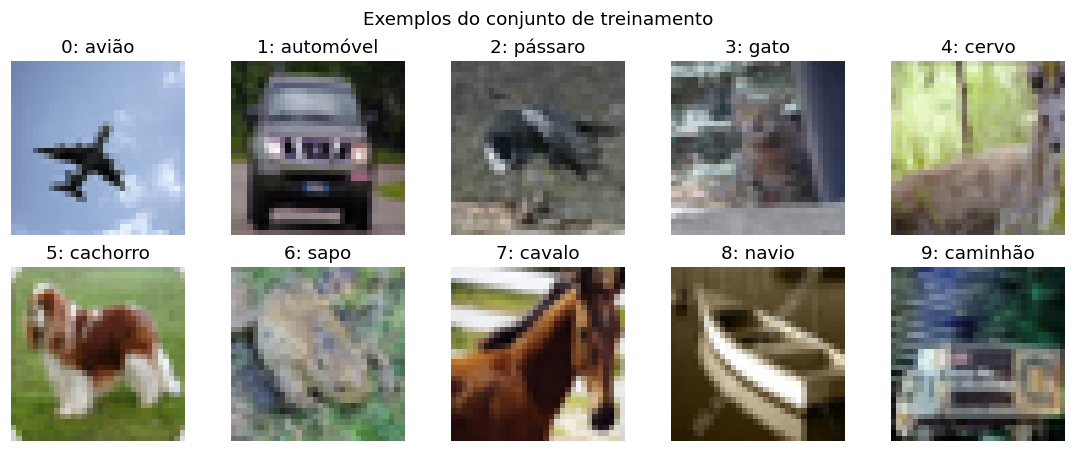

In [3]:
indices_treino, indices_validacao = train_test_split(
    np.arange(len(y_original)), test_size=5000,
    random_state=SEMENTE, stratify=y_original,
)
assert np.intersect1d(indices_treino, indices_validacao).size == 0
assert np.union1d(indices_treino, indices_validacao).size == 50000
assert np.array_equal(np.bincount(y_original[indices_treino]), np.full(10, 4500))
assert np.array_equal(np.bincount(y_original[indices_validacao]), np.full(10, 500))

base_original = TensorDataset(torch.from_numpy(X_original), torch.from_numpy(y_original))
base_teste = TensorDataset(torch.from_numpy(X_teste), torch.from_numpy(y_teste))
base_treino = Subset(base_original, indices_treino.tolist())
base_validacao = Subset(base_original, indices_validacao.tolist())

def criar_loader(base, embaralhar=False):
    return DataLoader(base, batch_size=LOTE, shuffle=embaralhar, num_workers=0,
                      pin_memory=DISPOSITIVO.type == 'cuda',
                      generator=torch.Generator().manual_seed(SEMENTE))

def preparar_imagens(x):
    return x.to(DISPOSITIVO, dtype=torch.float32).div_(127.5).sub_(1.0)

np.savez_compressed(SAIDA / 'indices_divisao.npz', treino=indices_treino,
                    validacao=indices_validacao)
print(f'Treino: {len(base_treino)} | Validação: {len(base_validacao)} | Teste: {len(base_teste)}')

fig, eixos = plt.subplots(2, 5, figsize=(10, 4), constrained_layout=True)
for classe, ax in enumerate(eixos.ravel()):
    indice = indices_treino[np.flatnonzero(y_original[indices_treino] == classe)[0]]
    ax.imshow(X_original[indice].transpose(1, 2, 0))
    ax.set_title(f'{classe}: {CLASSES[classe]}')
    ax.axis('off')
fig.suptitle('Exemplos do conjunto de treinamento')
fig.savefig(SAIDA / '01_exemplos_cifar10.png', bbox_inches='tight')
plt.show()
plt.close(fig)

## 3.4 — Arquiteturas dos classificadores MLP e CNN

- **MLP:** pixels achatados (3×32×32) → 256 → 128 → 10 logits.
- **CNN:** convoluções 3→16→32→64 com ReLU e max-pooling; representação 64×4×4 → 128 → 10 logits.

A função de perda `CrossEntropyLoss` recebe os **logits**, não probabilidades após softmax. A segunda convolução produzirá os mapas intermediários usados na Questão 4.

In [4]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.camadas = nn.Sequential(
            nn.Flatten(), nn.Linear(3 * 32 * 32, 256), nn.ReLU(), nn.Dropout(0.30),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.30), nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.camadas(x)


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.camadas = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 4 * 4, 128), nn.ReLU(),
            nn.Dropout(0.30), nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.camadas(x)


def descrever_arquitetura(modelo, nome):
    modelo.eval()
    x = torch.zeros(1, 3, 32, 32)
    linhas = []
    with torch.inference_mode():
        for camada in modelo.camadas:
            x = camada(x)
            linhas.append({'camada': str(camada), 'saida_sem_lote': str(tuple(x.shape[1:])),
                           'parametros': sum(p.numel() for p in camada.parameters())})
    assert x.shape == (1, 10)
    total = sum(linha['parametros'] for linha in linhas)
    assert total == sum(p.numel() for p in modelo.parameters())
    with (SAIDA / f'arquitetura_{nome}.csv').open('w', encoding='utf-8', newline='') as f:
        escritor = csv.DictWriter(f, fieldnames=linhas[0].keys())
        escritor.writeheader()
        escritor.writerows(linhas)
    texto = '\n'.join(f'{l["camada"]:<64} {l["saida_sem_lote"]:<14} {l["parametros"]:>10,}' for l in linhas)
    texto = f'{nome}: camada / formato de saída / parâmetros\n{texto}\nTotal: {total:,} parâmetros'
    (SAIDA / f'arquitetura_{nome}.txt').write_text(texto, encoding='utf-8')
    print(texto, '\n')
    return total

parametros = {nome: descrever_arquitetura(classe(), nome)
              for nome, classe in [('MLP', MLP), ('CNN', CNN)]}

MLP: camada / formato de saída / parâmetros
Flatten(start_dim=1, end_dim=-1)                                 (3072,)                 0
Linear(in_features=3072, out_features=256, bias=True)            (256,)            786,688
ReLU()                                                           (256,)                  0
Dropout(p=0.3, inplace=False)                                    (256,)                  0
Linear(in_features=256, out_features=128, bias=True)             (128,)             32,896
ReLU()                                                           (128,)                  0
Dropout(p=0.3, inplace=False)                                    (128,)                  0
Linear(in_features=128, out_features=10, bias=True)              (10,)               1,290
Total: 820,874 parâmetros 

CNN: camada / formato de saída / parâmetros
Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)) (16, 32, 32)          448
ReLU()                                                           

### Verificação automática das dimensões e do cálculo de gradientes
Esta célula usa tensores artificiais **somente para verificar a arquitetura**, não para medir acurácia. As métricas finais sempre virão do CIFAR-10.

In [5]:
for classe_modelo in (MLP, CNN):
    exemplo = torch.zeros(2, 3, 32, 32)
    rede_verificacao = classe_modelo()
    logits_verificacao = rede_verificacao(exemplo)
    assert logits_verificacao.shape == (2, 10)
    nn.functional.cross_entropy(logits_verificacao, torch.tensor([0, 1])).backward()
    assert all(p.grad is not None for p in rede_verificacao.parameters() if p.requires_grad)
    print(classe_modelo.__name__, 'saída:', tuple(logits_verificacao.shape),
          '| parâmetros:', sum(p.numel() for p in rede_verificacao.parameters()))
del rede_verificacao, exemplo, logits_verificacao

MLP saída: (2, 10) | parâmetros: 820874
CNN saída: (2, 10) | parâmetros: 156074


## 3.5 — Treinamento, validação e escolha da melhor época

Para ambos os modelos, a perda de treinamento e a de validação são calculadas no modo `eval()` **ao final de cada época**, para serem comparáveis. O teste não participa da escolha dos pesos. A CNN é treinada **uma única vez**: durante esse treinamento, também são guardados filtros da primeira convolução em cada época e estados completos em épocas selecionadas, necessários para a Questão 4.

A melhor época é aquela com **menor entropia cruzada de validação**, e seus pesos são restaurados antes de calcular as métricas finais. O treinamento pode parar antecipadamente quando não houver melhora.

In [6]:
@torch.inference_mode()
def avaliar(modelo, loader, guardar_predicoes=False):
    modelo.eval()
    soma_perda = 0.0
    acertos = 0
    quantidade = 0
    previsoes = []
    rotulos = []
    for imagens, classes in loader:
        imagens = preparar_imagens(imagens)
        classes = classes.to(DISPOSITIVO)
        logits = modelo(imagens)
        soma_perda += nn.functional.cross_entropy(logits, classes, reduction='sum').item()
        pred = logits.argmax(dim=1)
        acertos += (pred == classes).sum().item()
        quantidade += classes.numel()
        if guardar_predicoes:
            previsoes.append(pred.cpu().numpy())
            rotulos.append(classes.cpu().numpy())
    resultado = {'perda': soma_perda / quantidade, 'acuracia': acertos / quantidade}
    if guardar_predicoes:
        resultado.update(y_real=np.concatenate(rotulos), y_pred=np.concatenate(previsoes))
    return resultado


def copiar_pesos_cpu(modelo):
    """Snapshots independentes, válidos mesmo quando o treinamento usa CPU."""
    return {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}


def salvar_historico(nome, historico):
    with (SAIDA / f'historico_{nome}.csv').open('w', encoding='utf-8', newline='') as f:
        escritor = csv.DictWriter(f, fieldnames=historico[0].keys())
        escritor.writeheader()
        escritor.writerows(historico)


def treinar(classe_modelo, nome, registrar_filtros=False):
    # Esta função não recebe nem consulta o loader de teste.
    fixar_semente()
    modelo = classe_modelo().to(DISPOSITIVO)
    treino_loader = criar_loader(base_treino, embaralhar=True)
    treino_avaliacao = criar_loader(base_treino)
    validacao_loader = criar_loader(base_validacao)
    otimizador = torch.optim.Adam(modelo.parameters(), lr=TAXA_INICIAL, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        otimizador, mode='min', factor=0.5, patience=3, threshold=0.0)
    melhor_perda = float('inf')
    melhor_epoca = 0
    sem_melhora = 0
    historico = []
    inicio = time.perf_counter()
    caminho_pesos = SAIDA / f'pesos_{nome}.pt'
    # A CNN usada na Questão 4 é a mesma deste treinamento, sem recomeçar do zero.
    estados_cnn = {0: copiar_pesos_cpu(modelo)} if registrar_filtros else {}
    filtros_cnn = {0: modelo.camadas[0].weight.detach().cpu().clone()} if registrar_filtros else {}
    melhor_estado_cnn = None

    for epoca in range(1, EPOCAS_MAXIMAS + 1):
        modelo.train()
        soma_perda = 0.0
        taxa = otimizador.param_groups[0]['lr']
        for imagens, classes in treino_loader:
            imagens = preparar_imagens(imagens)
            classes = classes.to(DISPOSITIVO)
            otimizador.zero_grad(set_to_none=True)
            logits = modelo(imagens)
            perda = nn.functional.cross_entropy(logits, classes)
            perda.backward()
            otimizador.step()
            soma_perda += perda.item() * classes.numel()

        treino = avaliar(modelo, treino_avaliacao)
        validacao = avaliar(modelo, validacao_loader)
        linha = {'epoca': epoca, 'perda_treino': treino['perda'],
                 'perda_validacao': validacao['perda'],
                 'acuracia_treino': treino['acuracia'], 'acuracia_validacao': validacao['acuracia'],
                 'perda_durante_atualizacoes': soma_perda / len(base_treino),
                 'taxa_aprendizado': taxa}
        assert all(np.isfinite(v) for v in linha.values())
        historico.append(linha)
        salvar_historico(nome, historico)
        if registrar_filtros:
            filtros_cnn[epoca] = modelo.camadas[0].weight.detach().cpu().clone()
            if epoca in (1, 5, 10, 20):
                estados_cnn[epoca] = copiar_pesos_cpu(modelo)
        if validacao['perda'] < melhor_perda:
            melhor_perda = validacao['perda']
            melhor_epoca = epoca
            sem_melhora = 0
            estado_melhor = copiar_pesos_cpu(modelo)
            torch.save(estado_melhor, caminho_pesos)
            if registrar_filtros:
                melhor_estado_cnn = estado_melhor
        else:
            sem_melhora += 1
        scheduler.step(validacao['perda'])
        print(f'{nome} | época {epoca:02d} | perda treino {treino["perda"]:.4f} | '
              f'perda val. {validacao["perda"]:.4f} | acurácia val. {validacao["acuracia"]:.2%}', flush=True)
        if sem_melhora >= PACIENCIA:
            print(f'{nome}: parada antecipada após {PACIENCIA} épocas sem melhora.', flush=True)
            break

    if registrar_filtros:
        # Inclui a última época e a melhor época, mesmo se não forem 1/5/10/20.
        estados_cnn[epoca] = copiar_pesos_cpu(modelo)
        assert melhor_estado_cnn is not None
        estados_cnn[melhor_epoca] = melhor_estado_cnn
    modelo.load_state_dict(torch.load(caminho_pesos, map_location=DISPOSITIVO, weights_only=True))
    conferida = avaliar(modelo, validacao_loader)
    assert np.isclose(conferida['perda'], melhor_perda, rtol=1e-6)
    duracao = time.perf_counter() - inicio
    resumo = {'epocas_executadas': len(historico), 'epoca_selecionada': melhor_epoca,
              'menor_perda_validacao': melhor_perda, 'tempo_segundos': duracao}
    print(f'{nome}: pesos da época {melhor_epoca} restaurados; duração {duracao:.1f} s.\n', flush=True)
    registro_cnn = None
    if registrar_filtros:
        registro_cnn = {
            'estados': estados_cnn, 'filtros_por_epoca': filtros_cnn,
            'melhor_epoca': melhor_epoca, 'melhor_estado': melhor_estado_cnn,
            'historico': historico,
        }
        # Os pesos em uso e os pesos selecionados são rigorosamente os mesmos.
        assert all(torch.equal(modelo.state_dict()[k].cpu(), v)
                   for k, v in melhor_estado_cnn.items())
        torch.save(registro_cnn, SAIDA / 'representacoes_CNN.pt')
    return modelo, historico, resumo, registro_cnn

### Questão 3(a) — Treinamento da MLP

In [7]:
mlp, historico_mlp, resumo_mlp, _ = treinar(MLP, 'MLP', registrar_filtros=False)

MLP | época 01 | perda treino 1.5579 | perda val. 1.5905 | acurácia val. 43.20%
MLP | época 02 | perda treino 1.4647 | perda val. 1.5224 | acurácia val. 46.08%
MLP | época 03 | perda treino 1.3943 | perda val. 1.4713 | acurácia val. 47.74%
MLP | época 04 | perda treino 1.3291 | perda val. 1.4289 | acurácia val. 49.20%
MLP | época 05 | perda treino 1.3036 | perda val. 1.4100 | acurácia val. 49.54%
MLP | época 06 | perda treino 1.2803 | perda val. 1.4051 | acurácia val. 50.32%
MLP | época 07 | perda treino 1.2231 | perda val. 1.3739 | acurácia val. 51.26%
MLP | época 08 | perda treino 1.1944 | perda val. 1.3556 | acurácia val. 52.10%
MLP | época 09 | perda treino 1.1826 | perda val. 1.3632 | acurácia val. 51.90%
MLP | época 10 | perda treino 1.1396 | perda val. 1.3354 | acurácia val. 53.18%
MLP | época 11 | perda treino 1.1289 | perda val. 1.3397 | acurácia val. 52.16%
MLP | época 12 | perda treino 1.1105 | perda val. 1.3323 | acurácia val. 53.08%
MLP | época 13 | perda treino 1.0860 | p

### Questão 3(b) — Treinamento da CNN (reutilizada na Questão 4)

In [8]:
cnn, historico_cnn, resumo_cnn, execucao = treinar(CNN, 'CNN', registrar_filtros=True)
assert execucao is not None
print('A CNN abaixo será reutilizada diretamente na Questão 4; não haverá novo treinamento.')

CNN | época 01 | perda treino 1.4666 | perda val. 1.4558 | acurácia val. 47.12%
CNN | época 02 | perda treino 1.2966 | perda val. 1.2867 | acurácia val. 52.16%
CNN | época 03 | perda treino 1.1863 | perda val. 1.1951 | acurácia val. 56.92%
CNN | época 04 | perda treino 1.0973 | perda val. 1.1193 | acurácia val. 60.02%
CNN | época 05 | perda treino 1.0235 | perda val. 1.0490 | acurácia val. 62.58%
CNN | época 06 | perda treino 0.9683 | perda val. 1.0116 | acurácia val. 64.08%
CNN | época 07 | perda treino 0.9173 | perda val. 0.9760 | acurácia val. 65.36%
CNN | época 08 | perda treino 0.8585 | perda val. 0.9270 | acurácia val. 67.06%
CNN | época 09 | perda treino 0.7880 | perda val. 0.8715 | acurácia val. 69.96%
CNN | época 10 | perda treino 0.7756 | perda val. 0.8764 | acurácia val. 69.02%
CNN | época 11 | perda treino 0.7135 | perda val. 0.8366 | acurácia val. 70.44%
CNN | época 12 | perda treino 0.6922 | perda val. 0.8202 | acurácia val. 71.32%
CNN | época 13 | perda treino 0.6643 | p

## 3.6 — Teste final e matrizes de confusão

O conjunto de teste é consultado **somente após a seleção das épocas**. As matrizes possuem 10 linhas (classes reais) por 10 colunas (classes previstas), com exatamente 1.000 imagens em cada linha e total de 10.000 imagens.

In [9]:
modelos = {'MLP': mlp, 'CNN': cnn}
historicos = {'MLP': historico_mlp, 'CNN': historico_cnn}
resumos = {'MLP': resumo_mlp, 'CNN': resumo_cnn}
resultados = {}
matrizes = {}
teste_loader = criar_loader(base_teste)
for nome, modelo in modelos.items():
    resultado = avaliar(modelo, teste_loader, guardar_predicoes=True)
    assert np.array_equal(resultado['y_real'], y_teste)
    matriz = confusion_matrix(resultado['y_real'], resultado['y_pred'], labels=np.arange(10))
    acuracia = accuracy_score(resultado['y_real'], resultado['y_pred'])
    assert matriz.shape == (10, 10) and matriz.sum() == 10000
    assert np.array_equal(matriz.sum(axis=1), np.full(10, 1000))
    assert np.isclose(acuracia, resultado['acuracia'])
    assert np.isclose(matriz.trace() / matriz.sum(), acuracia)
    matrizes[nome] = matriz
    resultados[nome] = {'acuracia_teste': float(acuracia), 'perda_teste': resultado['perda'],
                        'acertos_teste': int(matriz.trace()), 'total_teste': int(matriz.sum()),
                        'parametros': parametros[nome], **resumos[nome]}
    np.savetxt(SAIDA / f'predicoes_teste_{nome}.csv',
               np.column_stack([np.arange(10000), y_teste, resultado['y_pred']]),
               delimiter=',', header='indice_teste,classe_real,classe_predita', comments='', fmt='%d')
    np.savetxt(SAIDA / f'matriz_confusao_{nome}.csv', matriz, delimiter=',', fmt='%d',
               header=','.join(CLASSES), comments='')
    relatorio = classification_report(y_teste, resultado['y_pred'], labels=np.arange(10),
                                      target_names=CLASSES, digits=4, zero_division=0)
    (SAIDA / f'relatorio_classes_{nome}.txt').write_text(relatorio, encoding='utf-8')
    print(f'{nome}: acurácia final {acuracia:.2%} ({matriz.trace()}/10.000); '
          f'perda de teste {resultado["perda"]:.4f}; época selecionada {resumos[nome]["epoca_selecionada"]}.')

MLP: acurácia final 56.13% (5613/10.000); perda de teste 1.2583; época selecionada 29.
CNN: acurácia final 72.93% (7293/10.000); perda de teste 0.8055; época selecionada 22.


## 3.7 — Resultados: curvas de erro, acurácias, matrizes e comparação

As curvas preservam as épocas realmente executadas; a linha vertical marca a época selecionada por validação. A acurácia final é calculada exclusivamente com o conjunto oficial de teste, sem números fixos ou inferidos previamente.

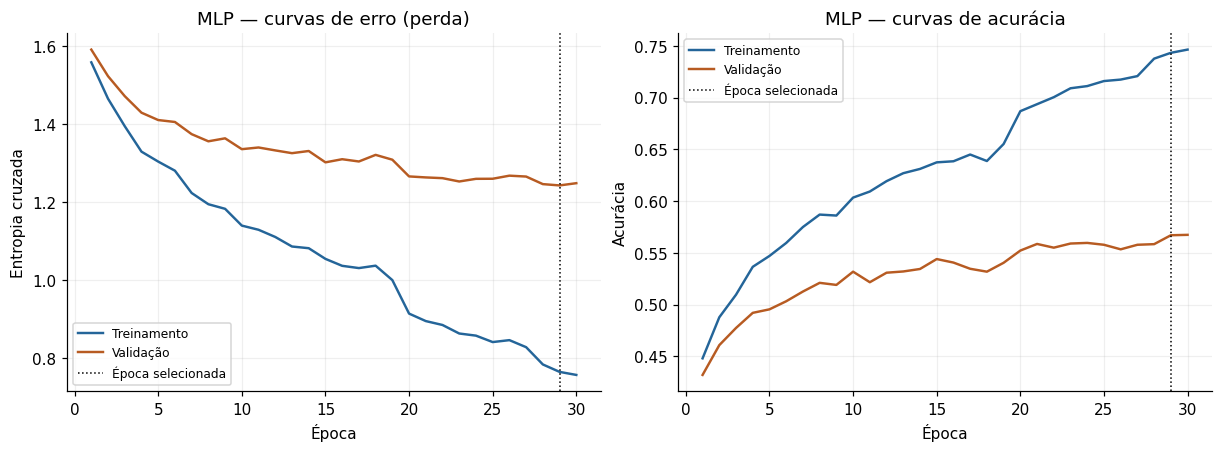

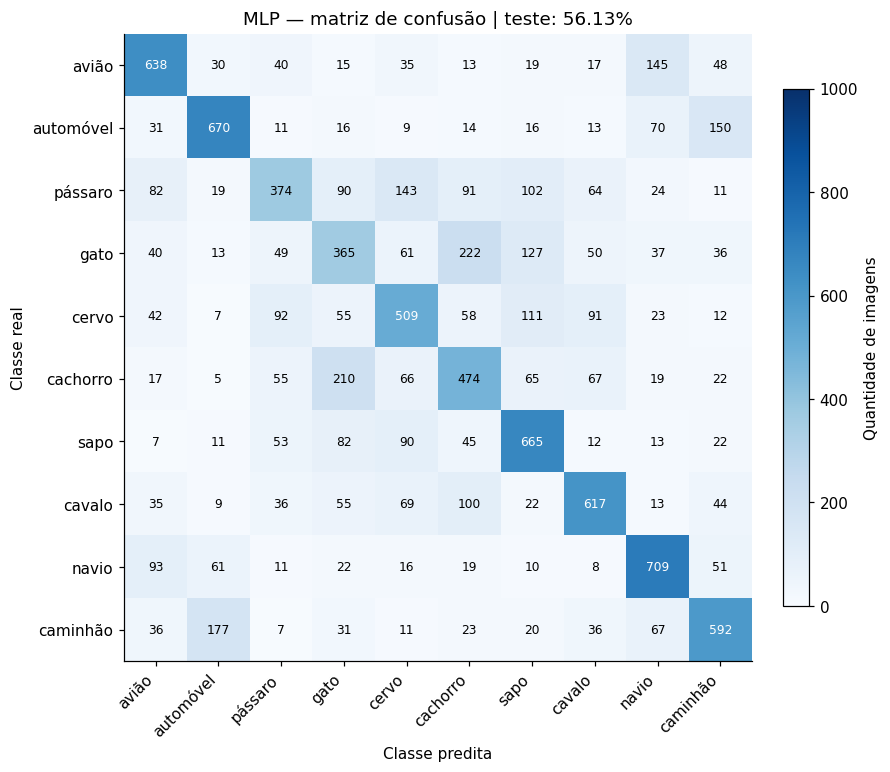

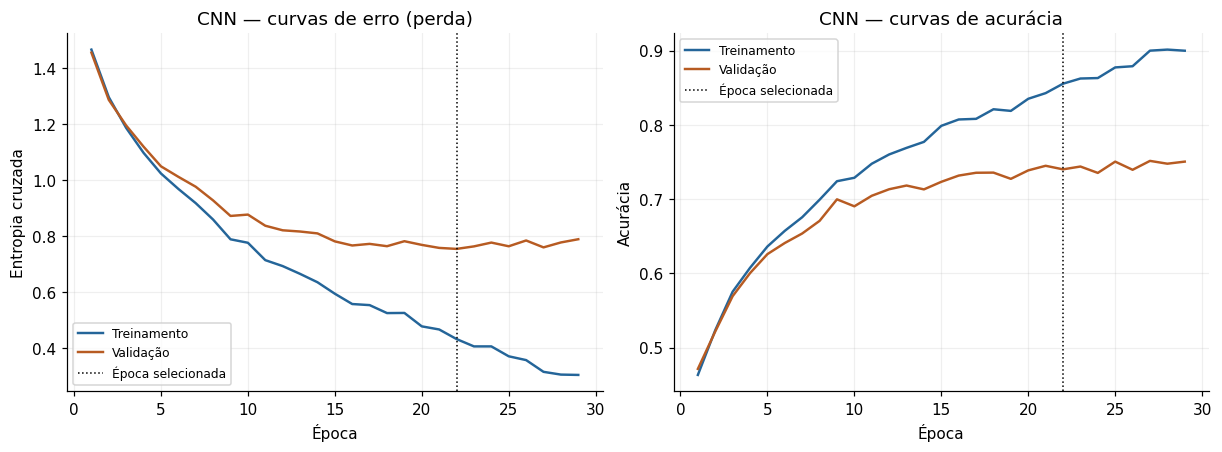

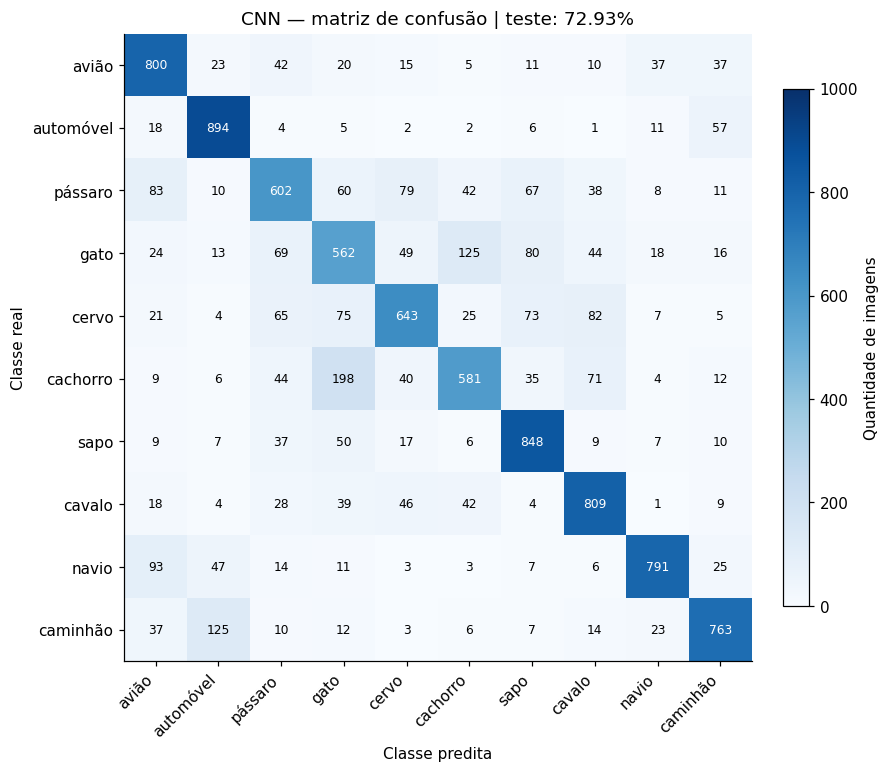

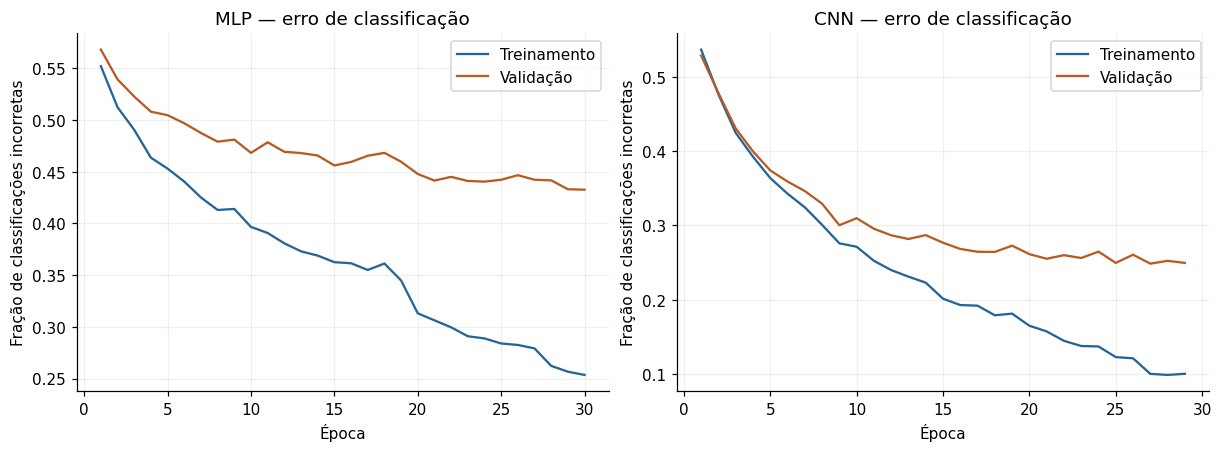

In [10]:
def desenhar_curvas(ax, nome, campo='perda'):
    historico = historicos[nome]
    epocas = [h['epoca'] for h in historico]
    for sufixo, rotulo, cor in [('treino', 'Treinamento', '#246599'),
                                ('validacao', 'Validação', '#b75b22')]:
        valores = [h[f'{campo}_{sufixo}'] for h in historico]
        ax.plot(epocas, valores, label=rotulo, color=cor, lw=1.6)
    ax.axvline(resumos[nome]['epoca_selecionada'], ls=':', color='black', lw=1, label='Época selecionada')
    ax.set(xlabel='Época', ylabel='Entropia cruzada' if campo == 'perda' else 'Acurácia',
           title=f'{nome} — curvas de ' + ('erro (perda)' if campo == 'perda' else 'acurácia'))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)


def desenhar_matriz(ax, nome):
    matriz = matrizes[nome]
    imagem = ax.imshow(matriz, cmap='Blues', vmin=0, vmax=1000)
    ax.set(xticks=np.arange(10), yticks=np.arange(10),
           xlabel='Classe predita', ylabel='Classe real',
           title=f'{nome} — matriz de confusão | teste: {resultados[nome]["acuracia_teste"]:.2%}')
    ax.set_xticklabels(CLASSES, rotation=45, ha='right')
    ax.set_yticklabels(CLASSES)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, str(matriz[i, j]), ha='center', va='center', fontsize=8,
                    color='white' if matriz[i, j] > 500 else 'black')
    return imagem


for nome in modelos:
    fig, eixos = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    desenhar_curvas(eixos[0], nome)
    desenhar_curvas(eixos[1], nome, campo='acuracia')
    fig.savefig(SAIDA / f'curvas_{nome}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
    imagem = desenhar_matriz(ax, nome)
    fig.colorbar(imagem, ax=ax, shrink=0.8, label='Quantidade de imagens')
    fig.savefig(SAIDA / f'matriz_confusao_{nome}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for nome, ax in zip(modelos, eixos):
    h = historicos[nome]
    ax.plot([e['epoca'] for e in h], [1-e['acuracia_treino'] for e in h], label='Treinamento', color='#246599')
    ax.plot([e['epoca'] for e in h], [1-e['acuracia_validacao'] for e in h], label='Validação', color='#b75b22')
    ax.set(title=f'{nome} — erro de classificação', xlabel='Época', ylabel='Fração de classificações incorretas')
    ax.grid(alpha=0.2)
    ax.legend()
fig.savefig(SAIDA / 'erro_classificacao.png', bbox_inches='tight')
plt.show()
plt.close(fig)

Modelo     Parâmetros   Melhor época   Acurácia teste    Perda teste
MLP           820,874             29          56.13%         1.2583
CNN           156,074             22          72.93%         0.8055
CNN − MLP: +16.80 pontos percentuais de acurácia no teste.


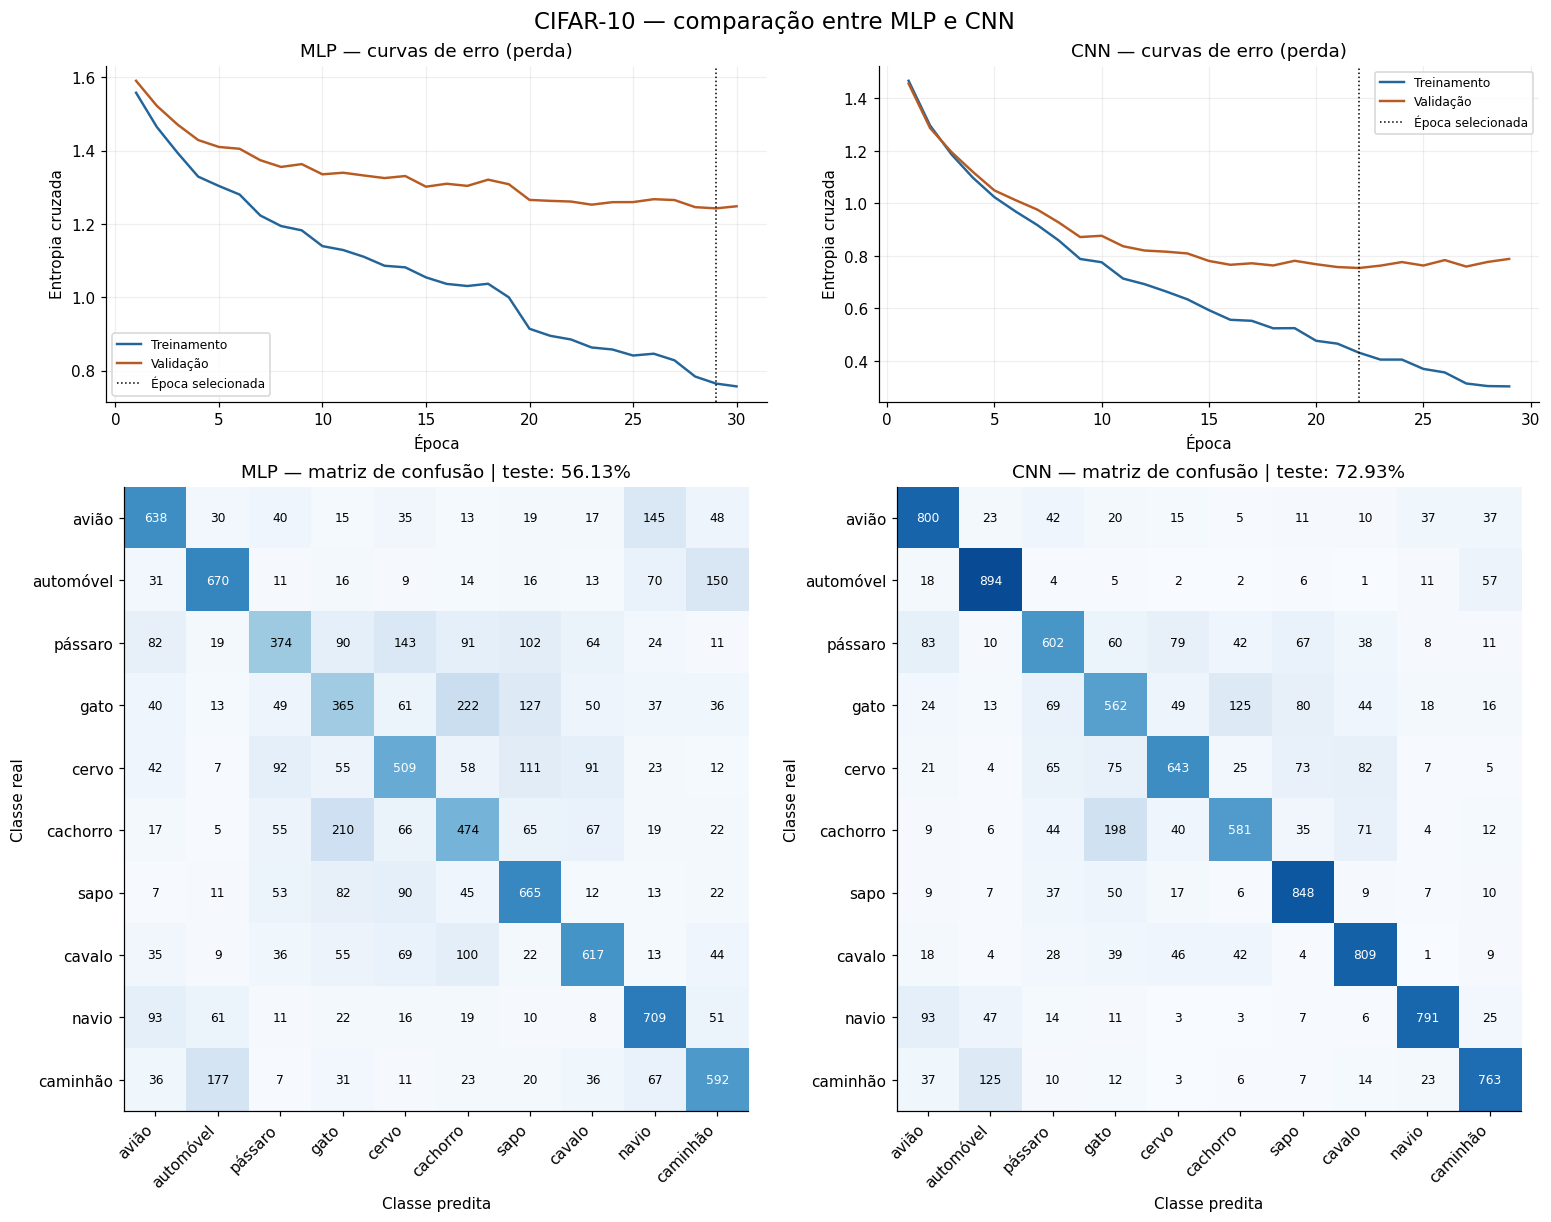

Arquivos salvos em: /content/resultados_cifar10
Verificações concluídas: integridade, divisão estratificada, formas das camadas, seleção e métricas.


In [11]:
print(f'{"Modelo":<8} {"Parâmetros":>12} {"Melhor época":>14} {"Acurácia teste":>16} {"Perda teste":>14}')
for nome, r in resultados.items():
    print(f'{nome:<8} {r["parametros"]:>12,} {r["epoca_selecionada"]:>14} '
          f'{r["acuracia_teste"]:>15.2%} {r["perda_teste"]:>14.4f}')
diferenca_pp = 100 * (resultados['CNN']['acuracia_teste'] - resultados['MLP']['acuracia_teste'])
print(f'CNN − MLP: {diferenca_pp:+.2f} pontos percentuais de acurácia no teste.')

fig, eixos = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True,
                           gridspec_kw={'height_ratios': [0.7, 1.3]})
for coluna, nome in enumerate(modelos):
    desenhar_curvas(eixos[0, coluna], nome)
    desenhar_matriz(eixos[1, coluna], nome)
fig.suptitle('CIFAR-10 — comparação entre MLP e CNN', fontsize=15)
fig.savefig(SAIDA / 'painel_comparativo.png', bbox_inches='tight')
plt.show()
plt.close(fig)

configuracao = {
    'dataset': 'CIFAR-10 oficial, versão Python', 'url': URL_BASE, 'md5': MD5_OFICIAL,
    'divisao': {'treino': 45000, 'validacao': 5000, 'teste': 10000},
    'semente': SEMENTE, 'classes': CLASSES, 'normalizacao': 'pixel / 127.5 - 1',
    'aumento_dados': False, 'pre_treinamento': False,
    'epocas_maximas': EPOCAS_MAXIMAS, 'patiencia_early_stopping': PACIENCIA,
    'batch_size': LOTE, 'otimizador': 'Adam', 'taxa_inicial': TAXA_INICIAL,
    'weight_decay': WEIGHT_DECAY,
    'scheduler': {'tipo': 'ReduceLROnPlateau', 'factor': 0.5, 'patience': 3, 'threshold': 0.0},
    'criterio_selecao': 'menor entropia cruzada na validação',
    'curvas_treino': 'avaliação de todo o treino ao fim de cada época, dropout desativado',
    'dispositivo': str(DISPOSITIVO), 'threads_cpu': torch.get_num_threads(),
    'versoes': versoes, 'resultados': resultados,
}
(SAIDA / 'configuracao_e_resultados.json').write_text(
    json.dumps(configuracao, ensure_ascii=False, indent=2), encoding='utf-8')
with (SAIDA / 'comparacao_final.csv').open('w', encoding='utf-8', newline='') as f:
    escritor = csv.DictWriter(f, fieldnames=['modelo'] + list(resultados['MLP'].keys()))
    escritor.writeheader()
    for nome, r in resultados.items():
        escritor.writerow({'modelo': nome, **r})
print('Arquivos salvos em:', SAIDA.resolve())
print('Verificações concluídas: integridade, divisão estratificada, formas das camadas, seleção e métricas.')

### Questão 3 — Interpretação dos resultados
A MLP ignora a vizinhança espacial explícita ao achatar a imagem, enquanto a CNN aprende filtros espaciais compartilhados. Compare **as acurácias de teste efetivamente impressas**, o formato das curvas e as linhas das matrizes, pois a diferença entre as redes é um resultado experimental, não algo que o notebook presume de antemão.

In [12]:
for nome in ('MLP', 'CNN'):
    matriz = matrizes[nome]
    desempenho_classe = np.diag(matriz) / matriz.sum(axis=1)
    mais_dificil = int(np.argmin(desempenho_classe))
    mais_facil = int(np.argmax(desempenho_classe))
    print(f'{nome}: acurácia no teste {resultados[nome]["acuracia_teste"]:.2%}; '
          f'menor recall por classe: {CLASSES[mais_dificil]} ({desempenho_classe[mais_dificil]:.2%}); '
          f'maior recall: {CLASSES[mais_facil]} ({desempenho_classe[mais_facil]:.2%}).')
assert resultados['CNN']['total_teste'] == resultados['MLP']['total_teste'] == 10000

MLP: acurácia no teste 56.13%; menor recall por classe: gato (36.50%); maior recall: navio (70.90%).
CNN: acurácia no teste 72.93%; menor recall por classe: gato (56.20%); maior recall: automóvel (89.40%).


---

## FIM DA QUESTÃO 3 — Conferência dos resultados

**A Questão 3 termina aqui.** Antes de prosseguir, devem aparecer os resultados dos dois modelos:

- **MLP:** arquitetura, histórico de treino/validação, curva de erro, matriz de confusão e acurácia de teste.
- **CNN:** arquitetura, histórico de treino/validação, curva de erro, matriz de confusão e acurácia de teste.
- **Comparação final:** resultados dos dois modelos e interpretação por classe. O treinamento da CNN já registrou os pesos usados na próxima questão.

**A partir da próxima seção, todas as células e figuras pertencem exclusivamente à Questão 4.**

---
# QUESTÃO 4 — Representações aprendidas pela CNN da Questão 3

**Objetivo:** investigar **a própria CNN treinada acima**, sem um novo treinamento.

**4(a)** — Visualizar filtros convolucionais e sua evolução.

**4(b)** — Exibir imagens originais, mapas intermediários de pelo menos cinco imagens do teste e interpretação qualitativa.

**4(c)** — Mostrar acertos e erros com classe real, prevista e probabilidade associada à predição.

O código usa `cnn` e os registros `execucao` criados na Questão 3, com verificação automática de igualdade de pesos. Os resultados desta seção são todos da **Questão 4**.

**Cuidado interpretativo:** ativação forte mostra resposta de um canal, não prova importância causal para uma classe.

In [13]:
# Garante que as representações pertencem exatamente à CNN avaliada na Questão 3.
MELHOR_EPOCA = resumo_cnn['epoca_selecionada']
assert execucao['melhor_epoca'] == MELHOR_EPOCA
assert execucao['historico'] == historico_cnn
assert all(torch.equal(cnn.state_dict()[k].detach().cpu(), w)
           for k, w in execucao['melhor_estado'].items())
assert execucao['filtros_por_epoca'][0].shape == (16, 3, 3, 3)
assert MELHOR_EPOCA in execucao['estados']
print('Verificado: CNN da Questão 4 = CNN selecionada e avaliada na Questão 3.')
print('Época selecionada:', MELHOR_EPOCA)

Verificado: CNN da Questão 4 = CNN selecionada e avaliada na Questão 3.
Época selecionada: 22


## Questão 4(a) — Visualização dos filtros da primeira camada convolucional

São apresentados os 16 filtros RGB (16 × 3 × 3 × 3), os valores assinados por canal do filtro mais alterado e a **evolução dos pesos desde a inicialização**, registrados durante o treinamento da Questão 3. A visualização RGB aplica escala comum entre épocas, evitando comparar filtros com normalizações arbitrariamente diferentes.

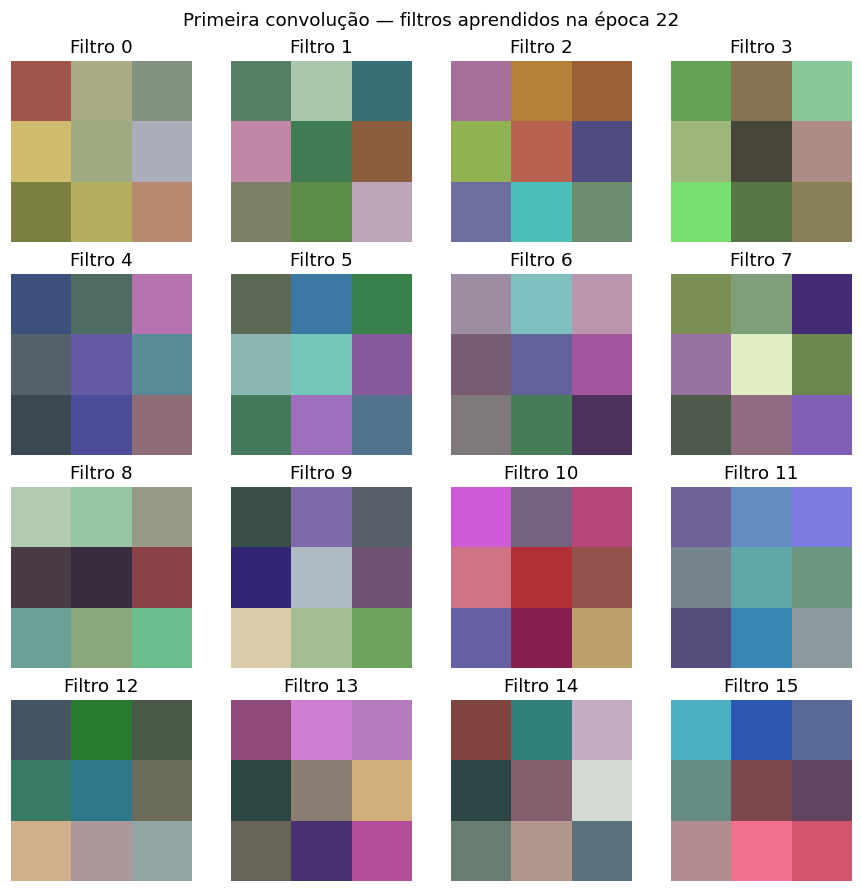

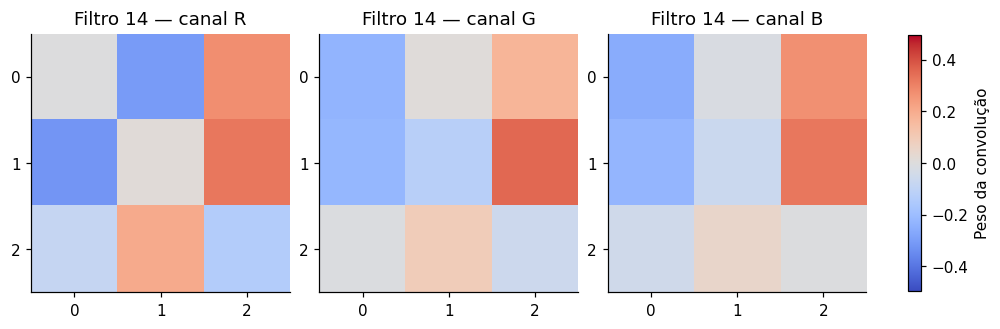

Leitura qualitativa dos filtros:
- Na representação RGB, cinza representa peso zero; as cores codificam pesos por canal.
- Contrastes entre posições e canais sugerem sensibilidade a padrões locais de intensidade e cor.
- Filtros 3×3 não permitem, isoladamente, afirmar que um neurônio detecta um objeto específico.
- O filtro 14 apresentou a maior mudança L2 desde a inicialização: 0.6581.


In [14]:
# (a) Todos os filtros da primeira camada convolucional.
# Os pesos têm forma [16, 3, 3, 3]: filtro, canal RGB, altura e largura.
# Uma escala comum evita criar diferenças visuais por normalização individual.
pesos_iniciais = execucao['filtros_por_epoca'][0].numpy()
pesos_finais = cnn.camadas[0].weight.detach().cpu().numpy()
assert pesos_finais.shape == (16, 3, 3, 3)
limite_pesos = max(float(w.abs().max()) for w in execucao['filtros_por_epoca'].values())
limite_pesos = max(limite_pesos, 1e-12)

def filtro_rgb(pesos):
    return np.clip(0.5 + pesos.transpose(1, 2, 0) / (2 * limite_pesos), 0, 1)

fig, eixos = plt.subplots(4, 4, figsize=(8, 8), constrained_layout=True)
for i, ax in enumerate(eixos.ravel()):
    ax.imshow(filtro_rgb(pesos_finais[i]), interpolation='nearest')
    ax.set_title(f'Filtro {i}')
    ax.axis('off')
fig.suptitle(f'Primeira convolução — filtros aprendidos na época {MELHOR_EPOCA}')
fig.savefig(SAIDA / 'q4_filtros_rgb.png', bbox_inches='tight')
plt.show()
plt.close(fig)

# Escala explícita dos pesos positivos e negativos por canal do filtro mais alterado.
mudancas = np.linalg.norm((pesos_finais - pesos_iniciais).reshape(16, -1), axis=1)
filtro_destacado = int(np.argmax(mudancas))
fig, eixos = plt.subplots(1, 3, figsize=(9, 3), constrained_layout=True)
for canal, (nome, ax) in enumerate(zip(['R', 'G', 'B'], eixos)):
    imagem = ax.imshow(pesos_finais[filtro_destacado, canal], cmap='coolwarm',
                       vmin=-limite_pesos, vmax=limite_pesos, interpolation='nearest')
    ax.set_title(f'Filtro {filtro_destacado} — canal {nome}')
    ax.set_xticks([0, 1, 2])
    ax.set_yticks([0, 1, 2])
fig.colorbar(imagem, ax=eixos, label='Peso da convolução', shrink=0.8)
fig.savefig(SAIDA / 'q4_filtros_canais.png', bbox_inches='tight')
plt.show()
plt.close(fig)

print('Leitura qualitativa dos filtros:')
print('- Na representação RGB, cinza representa peso zero; as cores codificam pesos por canal.')
print('- Contrastes entre posições e canais sugerem sensibilidade a padrões locais de intensidade e cor.')
print('- Filtros 3×3 não permitem, isoladamente, afirmar que um neurônio detecta um objeto específico.')
print(f'- O filtro {filtro_destacado} apresentou a maior mudança L2 desde a inicialização: '
      f'{mudancas[filtro_destacado]:.4f}.')

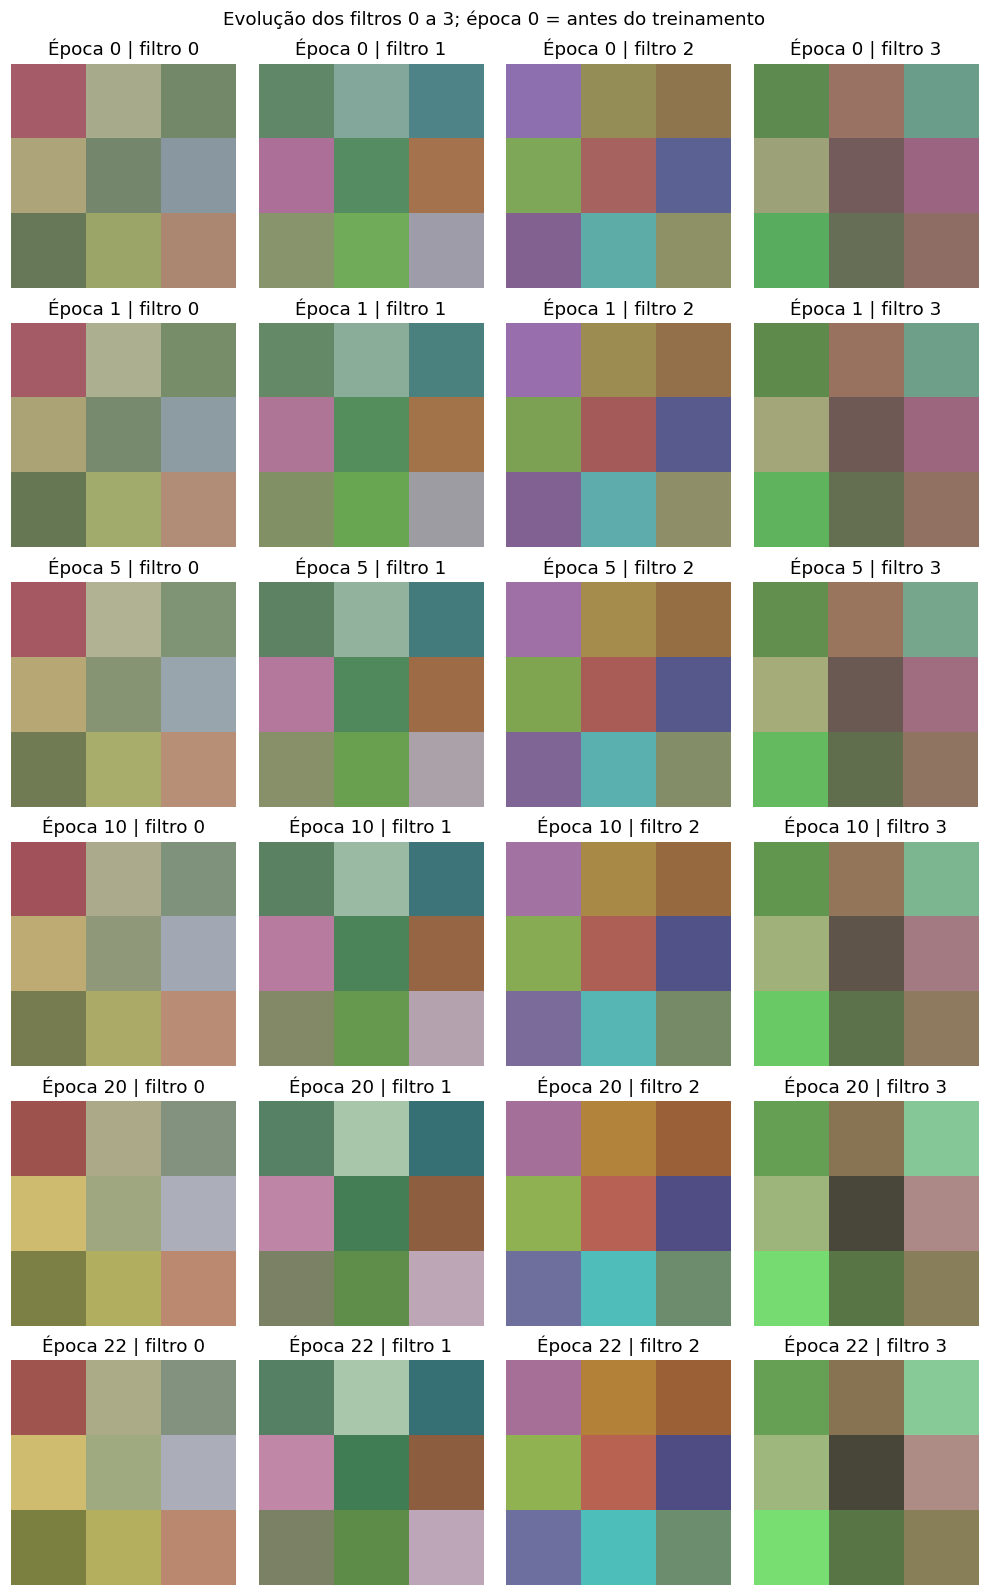

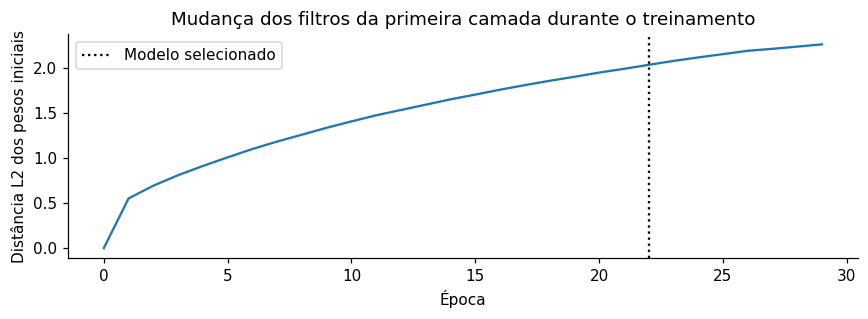

In [15]:
# Evolução temporal dos filtros: mesmos índices e mesma escala de cores.
epocas_visuais = sorted({0, MELHOR_EPOCA} | {
    epoca for epoca in (1, 5, 10, 20) if epoca in execucao['estados'] and epoca <= MELHOR_EPOCA
})
assert set(epocas_visuais).issubset(execucao['estados'])
fig, eixos = plt.subplots(len(epocas_visuais), 4,
                         figsize=(9, 2.4 * len(epocas_visuais)), squeeze=False,
                         constrained_layout=True)
for linha, epoca in enumerate(epocas_visuais):
    pesos = execucao['filtros_por_epoca'][epoca].numpy()
    for filtro in range(4):
        ax = eixos[linha, filtro]
        ax.imshow(filtro_rgb(pesos[filtro]), interpolation='nearest')
        ax.set_title(f'Época {epoca} | filtro {filtro}')
        ax.axis('off')
fig.suptitle('Evolução dos filtros 0 a 3; época 0 = antes do treinamento')
fig.savefig(SAIDA / 'q4_evolucao_filtros.png', bbox_inches='tight')
plt.show()
plt.close(fig)

epocas = sorted(execucao['filtros_por_epoca'])
variacao = [np.linalg.norm((execucao['filtros_por_epoca'][e].numpy() - pesos_iniciais).ravel())
            for e in epocas]
plt.figure(figsize=(8, 3))
plt.plot(epocas, variacao)
plt.axvline(MELHOR_EPOCA, color='black', linestyle=':', label='Modelo selecionado')
plt.xlabel('Época')
plt.ylabel('Distância L2 dos pesos iniciais')
plt.title('Mudança dos filtros da primeira camada durante o treinamento')
plt.legend()
plt.tight_layout()
plt.savefig(SAIDA / 'q4_distancia_filtros.png', bbox_inches='tight')
plt.show()
plt.close()

## Questão 4(b) — Mapas de ativação de cinco imagens do teste

Para cinco imagens do conjunto oficial de teste, extraem-se **32 mapas de 16 × 16** da segunda convolução (após ReLU, antes do segundo pooling). As figuras exibem a imagem original, uma sobreposição e os oito canais de maior ativação média. Uma análise quantitativa local indica os quadrantes com maiores respostas, distinguindo **ativação** de **importância causal para a predição**.

In [16]:
# Previsões de todo o teste, somente após o treinamento e a seleção pela validação.
@torch.inference_mode()
def probabilidades_teste(modelo):
    modelo.eval()
    partes = []
    for imagens, _ in criar_loader(base_teste):
        logits = modelo(preparar_imagens(imagens))
        partes.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(partes)

probabilidades = probabilidades_teste(cnn)
predicoes = probabilidades.argmax(axis=1)
confiancas = probabilidades[np.arange(len(predicoes)), predicoes]
assert probabilidades.shape == (10000, 10)
assert np.all(np.isfinite(probabilidades))
assert np.allclose(probabilidades.sum(axis=1), 1, atol=1e-6)
assert np.array_equal(predicoes, np.loadtxt(SAIDA / 'predicoes_teste_CNN.csv', delimiter=',', skiprows=1, usecols=2, dtype=int))
assert np.isclose((predicoes == y_teste).mean(), resultados['CNN']['acuracia_teste'])
print(f'Acurácia no teste (mesma CNN da Q3): {(predicoes == y_teste).mean():.2%}')
# Softmax fornece a probabilidade estimada pelo modelo; não garante calibração.

Acurácia no teste (mesma CNN da Q3): 72.93%


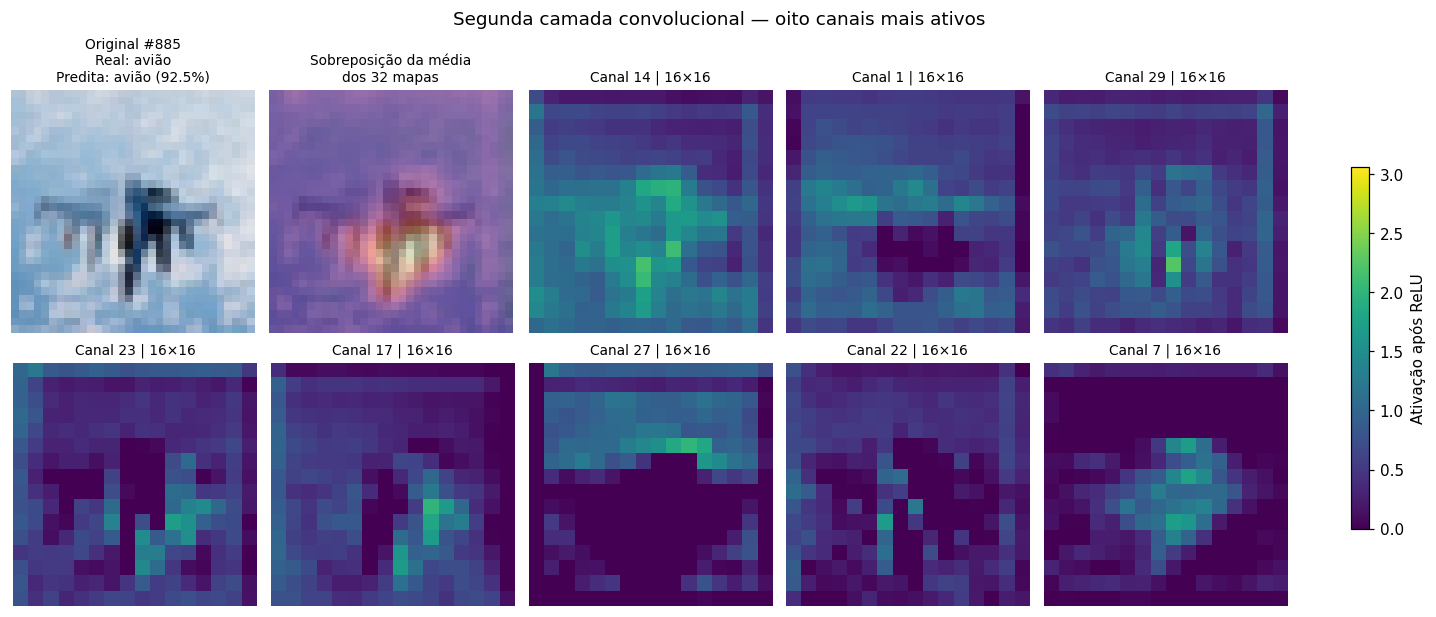

Imagem #885: maior soma de ativação na região inferior direita (31.0% do total); pico na célula (10, 9) do mapa 16×16, com índices iniciados em zero.


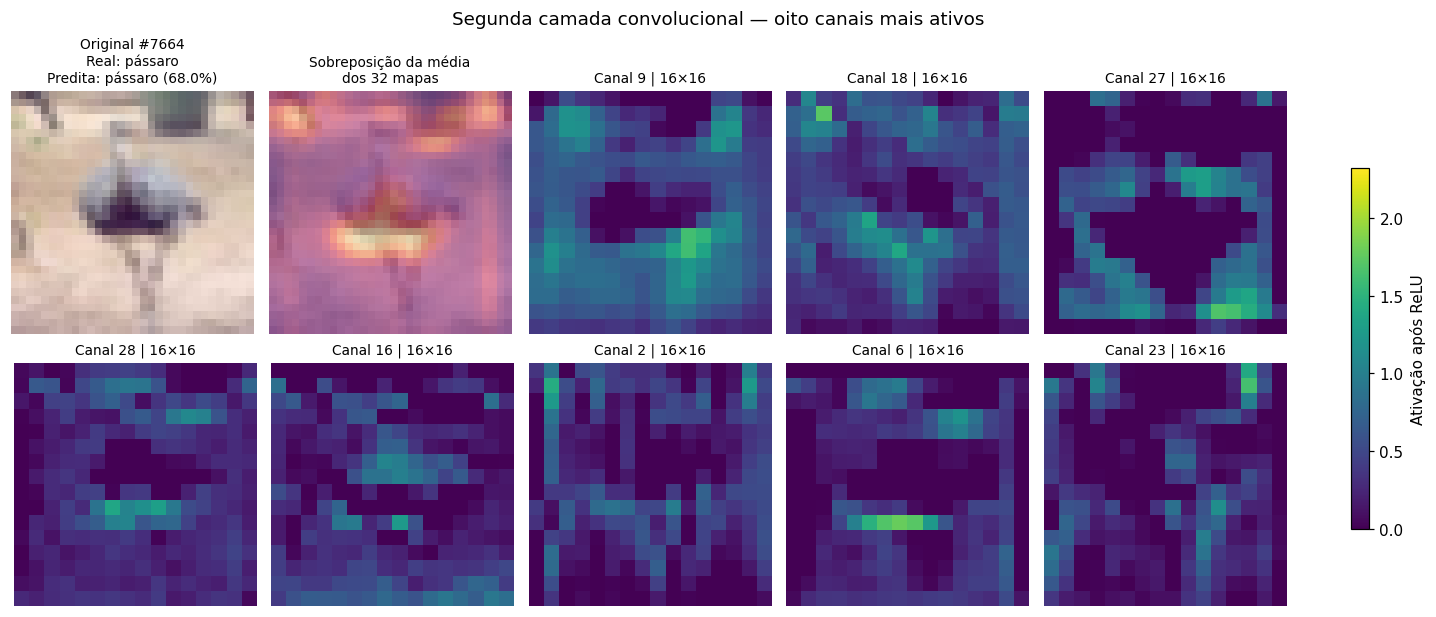

Imagem #7664: maior soma de ativação na região superior direita (25.3% do total); pico na célula (9, 6) do mapa 16×16, com índices iniciados em zero.


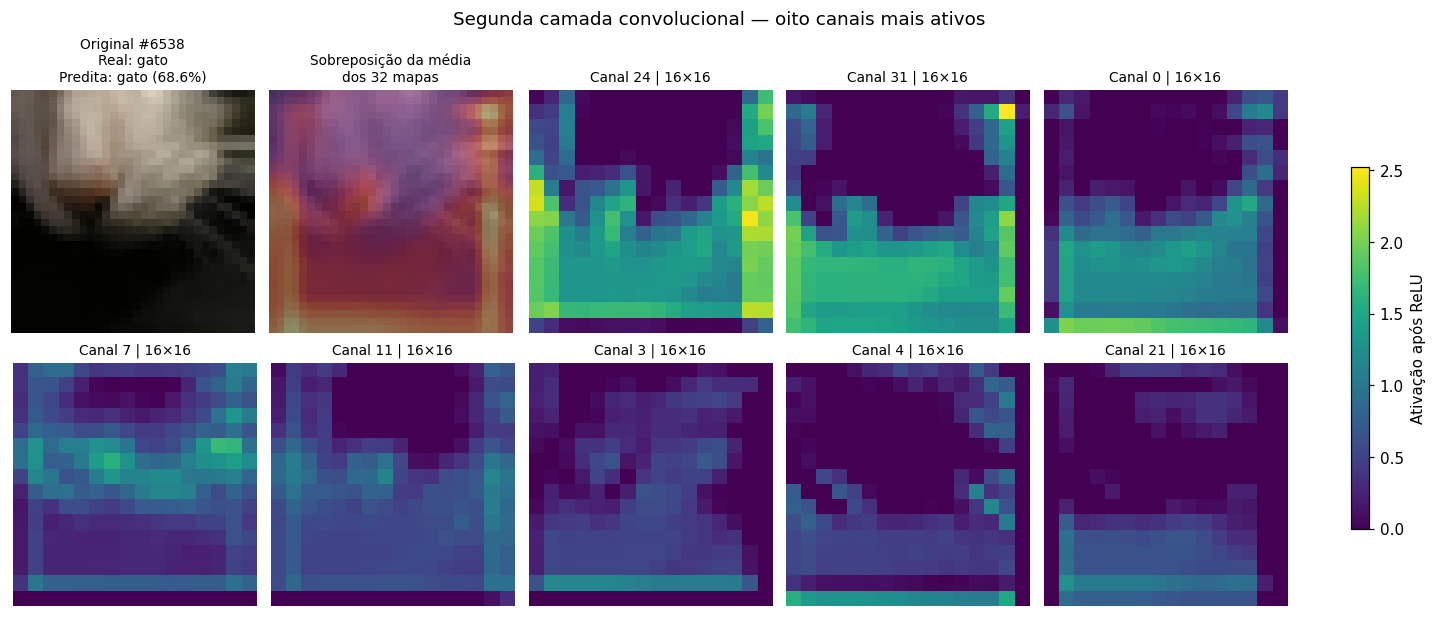

Imagem #6538: maior soma de ativação na região inferior esquerda (30.7% do total); pico na célula (1, 14) do mapa 16×16, com índices iniciados em zero.


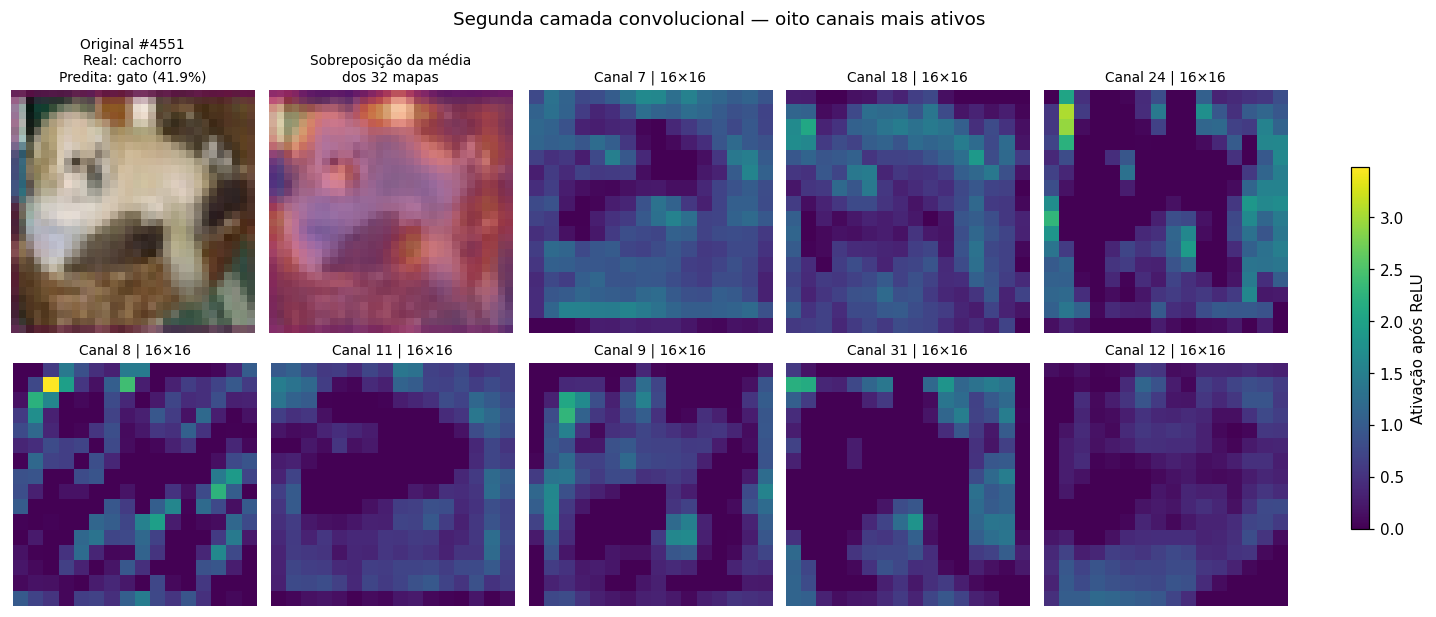

Imagem #4551: maior soma de ativação na região inferior direita (26.0% do total); pico na célula (2, 1) do mapa 16×16, com índices iniciados em zero.


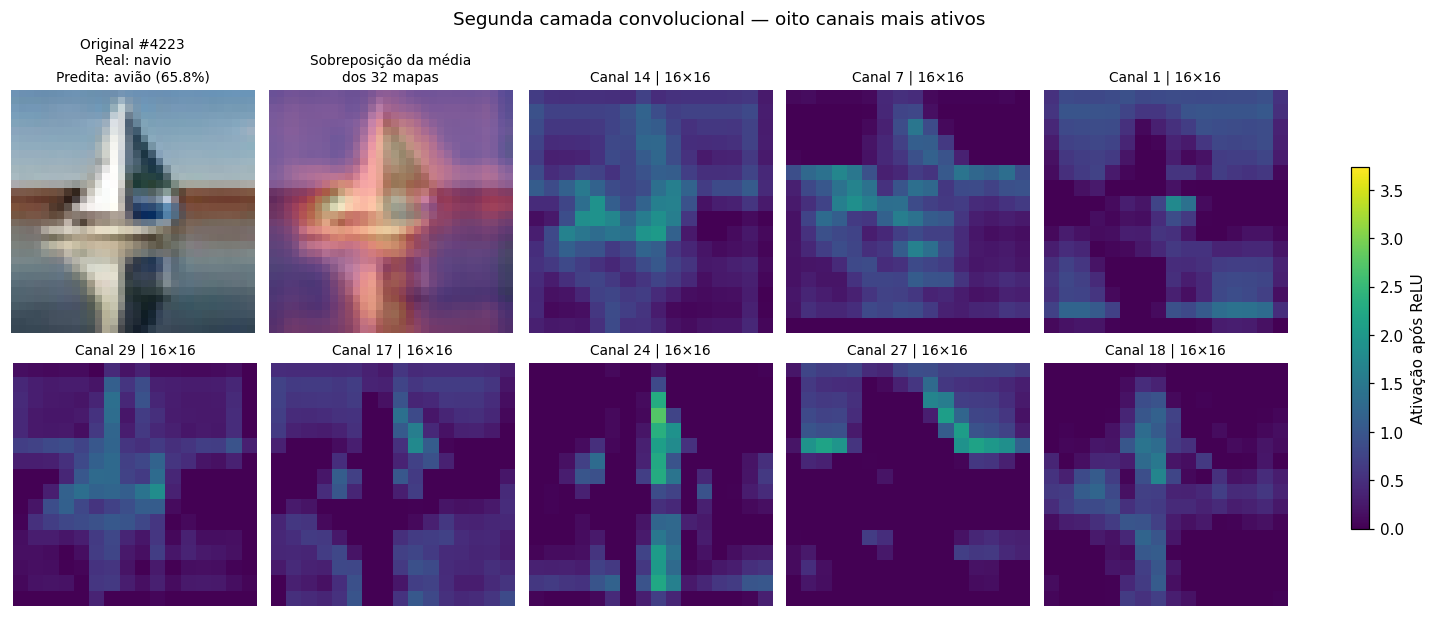

Imagem #4223: maior soma de ativação na região inferior esquerda (26.2% do total); pico na célula (7, 4) do mapa 16×16, com índices iniciados em zero.
A sobreposição localiza respostas fortes e permite compará-las aos contornos, texturas e fundo.
A média resume os canais, mas pode ocultar respostas individuais. Não é uma probabilidade.
Ativação elevada não demonstra contribuição causal para a classe prevista.


In [17]:
# (b) Cinco imagens de classes diferentes, escolhidas de forma reprodutível.
rng_imagens = np.random.default_rng(SEMENTE)
classes_selecionadas = [0, 2, 3, 5, 8]
indices_imagens = np.array([
    int(rng_imagens.choice(np.flatnonzero(y_teste == classe)))
    for classe in classes_selecionadas
])
assert len(np.unique(indices_imagens)) >= 5

@torch.inference_mode()
def extrair_ativacoes(modelo, imagens):
    modelo.eval()
    capturas = []
    def capturar(camada, entradas, saida):
        capturas.append(saida.detach().cpu())
    # Segunda convolução, depois da ReLU e antes do segundo MaxPool.
    gancho = modelo.camadas[4].register_forward_hook(capturar)
    try:
        modelo(preparar_imagens(torch.from_numpy(imagens)))
    finally:
        gancho.remove()
    assert len(capturas) == 1
    return capturas[0].numpy()

mapas = extrair_ativacoes(cnn, X_teste[indices_imagens])
assert mapas.shape == (5, 32, 16, 16)
assert np.all(mapas >= 0)  # ReLU elimina valores negativos.

def mapa_medio_ampliado(ativacoes):
    medio = ativacoes.mean(axis=0)
    ampliado = nn.functional.interpolate(
        torch.from_numpy(medio)[None, None], size=(32, 32),
        mode='bilinear', align_corners=False
    )[0, 0].numpy()
    return medio, ampliado

for posicao, indice in enumerate(indices_imagens):
    original = X_teste[indice].transpose(1, 2, 0)
    ativacoes = mapas[posicao]
    media, ampliado = mapa_medio_ampliado(ativacoes)
    # Mostra os oito canais com maior ativação média; os 32 ficam em mapas[posicao].
    canais = np.argsort(ativacoes.mean(axis=(1, 2)), kind='stable')[-8:][::-1]
    limite = max(float(ativacoes.max()), 1e-12)
    fig, eixos = plt.subplots(2, 5, figsize=(13, 5.5), constrained_layout=True)
    axes = eixos.ravel()
    axes[0].imshow(original)
    axes[0].set_title(f'Original #{indice}\nReal: {CLASSES[y_teste[indice]]}\n'
                      f'Predita: {CLASSES[predicoes[indice]]} ({confiancas[indice]:.1%})', fontsize=9)
    axes[1].imshow(original)
    axes[1].imshow(ampliado, cmap='magma', alpha=0.55,
                   vmin=0, vmax=max(float(ampliado.max()), 1e-12))
    axes[1].set_title('Sobreposição da média\ndos 32 mapas', fontsize=9)
    for ax, canal in zip(axes[2:], canais):
        imagem = ax.imshow(ativacoes[canal], cmap='viridis', vmin=0, vmax=limite,
                           interpolation='nearest')
        ax.set_title(f'Canal {canal} | 16×16', fontsize=9)
    for ax in axes:
        ax.axis('off')
    fig.colorbar(imagem, ax=list(axes[2:]), shrink=0.7, label='Ativação após ReLU')
    fig.suptitle('Segunda camada convolucional — oito canais mais ativos')
    fig.savefig(SAIDA / f'q4_ativacoes_imagem_{indice}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

    # Descrição espacial objetiva; não atribui significado semântico automaticamente.
    regioes = {
        'superior esquerda': float(media[:8, :8].sum()),
        'superior direita': float(media[:8, 8:].sum()),
        'inferior esquerda': float(media[8:, :8].sum()),
        'inferior direita': float(media[8:, 8:].sum()),
    }
    total = sum(regioes.values())
    if total > 0:
        regiao = max(regioes, key=regioes.get)
        linha, coluna = np.unravel_index(np.argmax(media), media.shape)
        print(f'Imagem #{indice}: maior soma de ativação na região {regiao} '
              f'({regioes[regiao] / total:.1%} do total); pico na célula '
              f'({linha}, {coluna}) do mapa 16×16, com índices iniciados em zero.')
    else:
        print(f'Imagem #{indice}: todos os mapas estão inativos após a ReLU.')

print('A sobreposição localiza respostas fortes e permite compará-las aos contornos, texturas e fundo.')
print('A média resume os canais, mas pode ocultar respostas individuais. Não é uma probabilidade.')
print('Ativação elevada não demonstra contribuição causal para a classe prevista.')

### Questão 4(b) — Evolução dos mapas nas mesmas cinco imagens
Os estados de épocas anteriores são cópias salvas **durante o treinamento da CNN da Questão 3**. A comparação utiliza a mesma seleção de imagens e a mesma escala por linha, permitindo observar mudanças sem introduzir um modelo treinado separadamente.

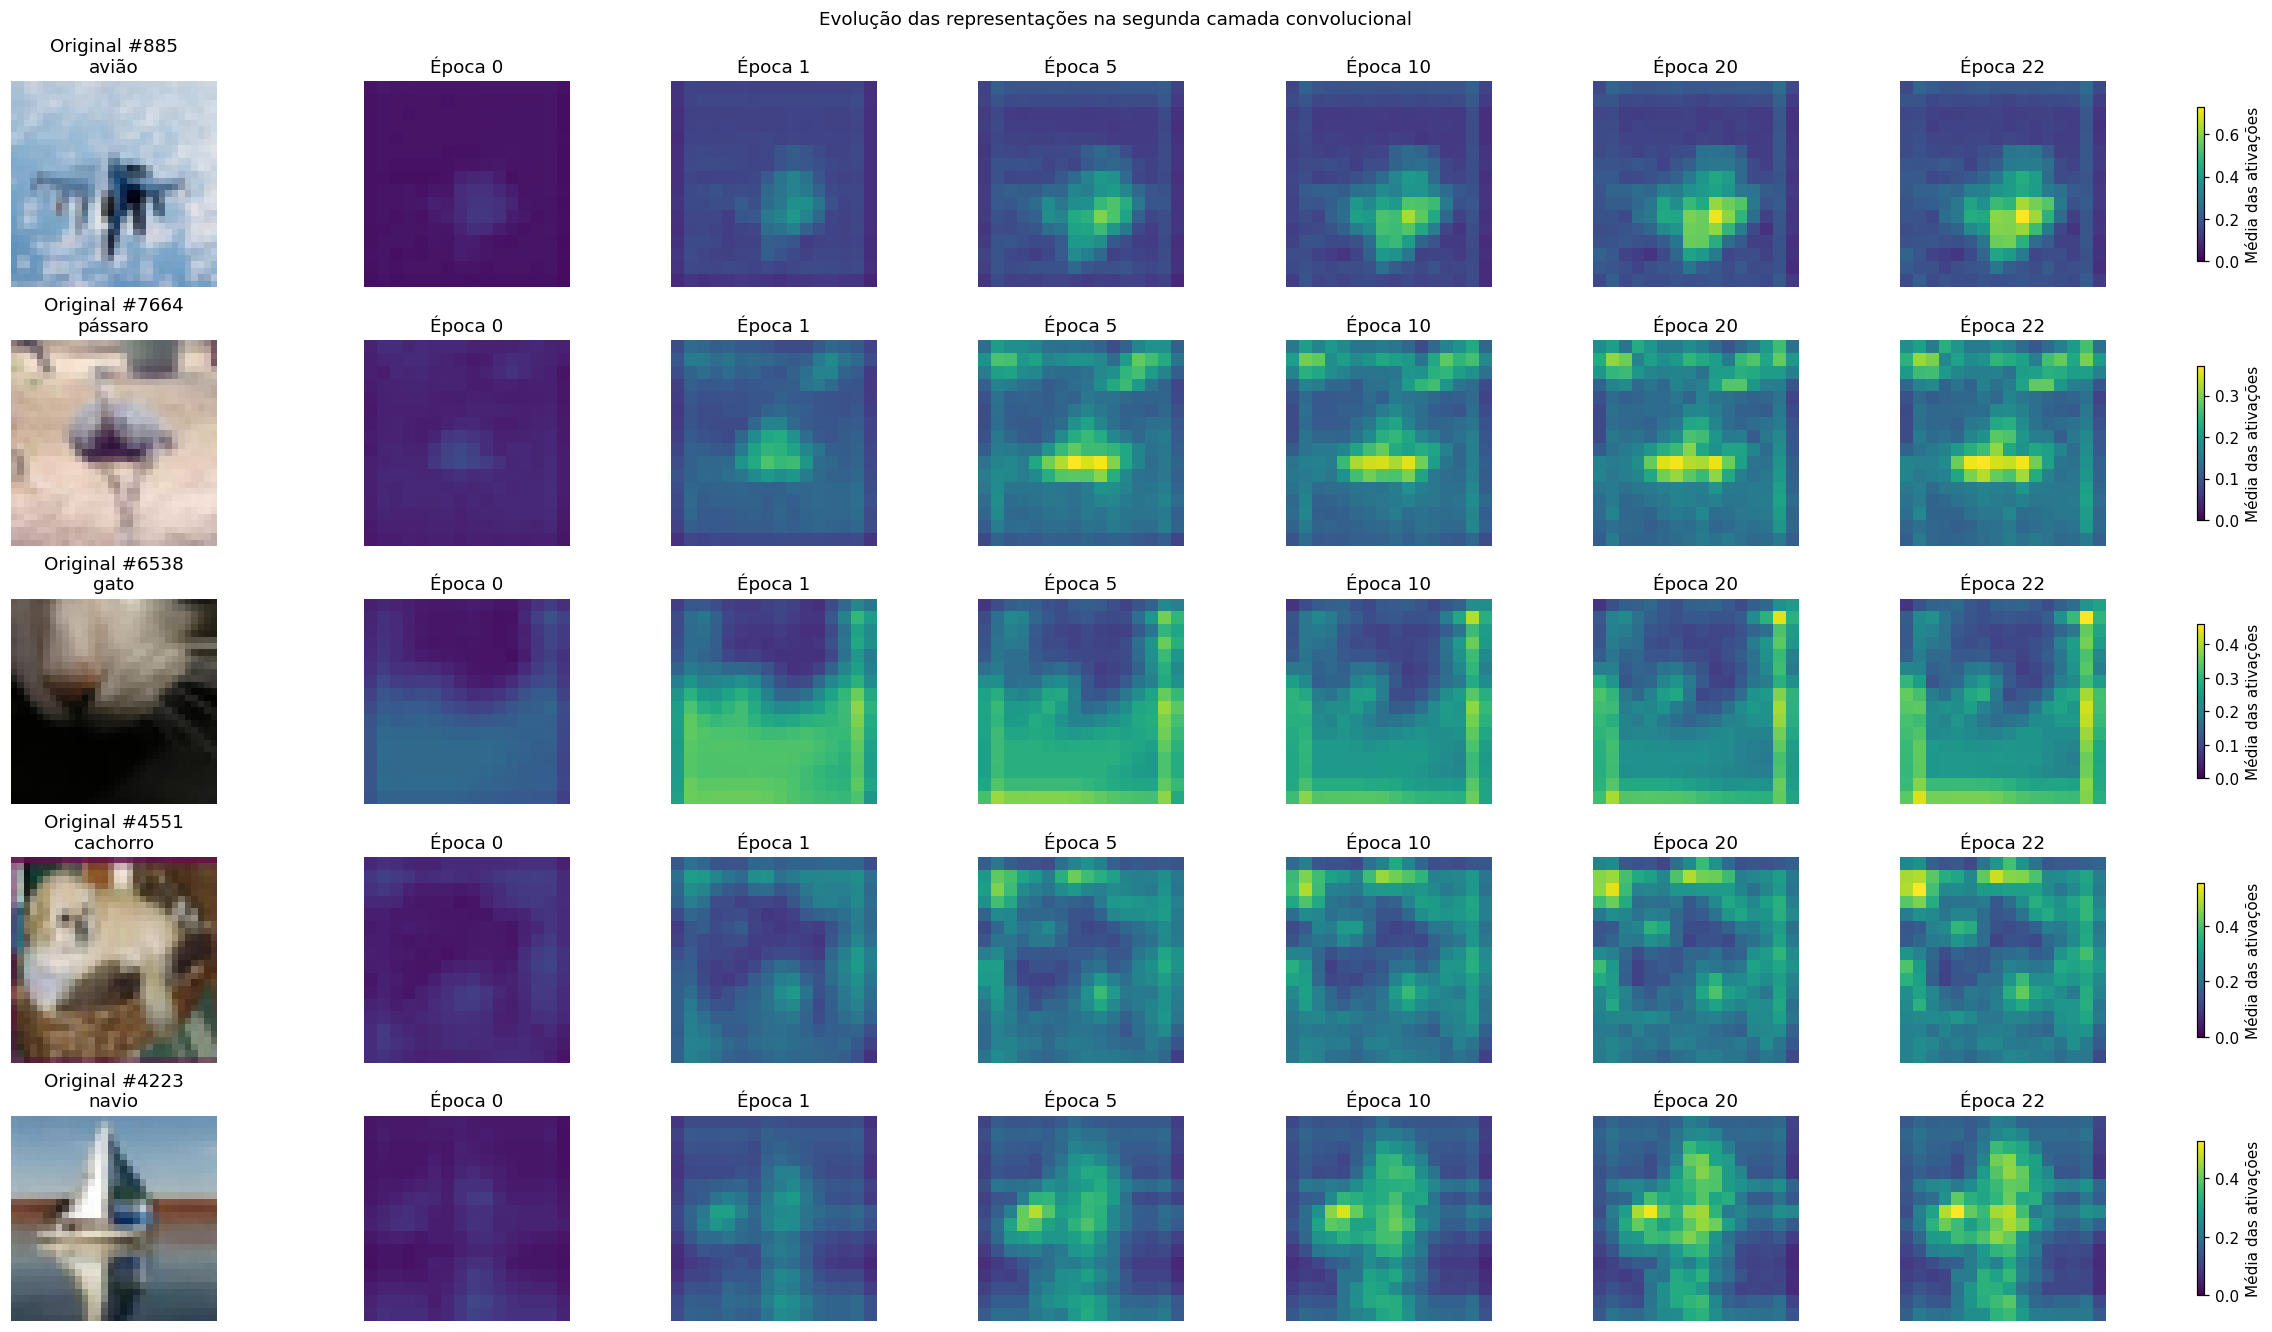

In [18]:
# Mapas intermediários ao longo do treinamento para as mesmas cinco imagens.
# Mantém os índices das imagens e uma escala comum por linha entre as épocas.
mapas_temporais = {}
modelo_temporal = CNN().to(DISPOSITIVO)
for epoca in epocas_visuais:
    modelo_temporal.load_state_dict(execucao['estados'][epoca])
    mapas_temporais[epoca] = extrair_ativacoes(modelo_temporal, X_teste[indices_imagens])

fig, eixos = plt.subplots(5, len(epocas_visuais) + 1,
                         figsize=(3 * (len(epocas_visuais) + 1), 12),
                         squeeze=False, constrained_layout=True)
for linha, indice in enumerate(indices_imagens):
    eixos[linha, 0].imshow(X_teste[indice].transpose(1, 2, 0))
    eixos[linha, 0].set_title(f'Original #{indice}\n{CLASSES[y_teste[indice]]}')
    medias = [mapas_temporais[e][linha].mean(axis=0) for e in epocas_visuais]
    limite = max(max(float(m.max()) for m in medias), 1e-12)
    for coluna, (epoca, media) in enumerate(zip(epocas_visuais, medias), start=1):
        im = eixos[linha, coluna].imshow(media, cmap='viridis', vmin=0, vmax=limite,
                                        interpolation='nearest')
        eixos[linha, coluna].set_title(f'Época {epoca}')
    fig.colorbar(im, ax=list(eixos[linha, 1:]), shrink=0.75, label='Média das ativações')
    for ax in eixos[linha]:
        ax.axis('off')
fig.suptitle('Evolução das representações na segunda camada convolucional')
fig.savefig(SAIDA / 'q4_evolucao_ativacoes.png', bbox_inches='tight')
plt.show()
plt.close(fig)
del modelo_temporal

### Questão 4(b) — Interpretação qualitativa das regiões ativadas

As imagens e mapas acima devem ser interpretados visualmente. O texto a seguir explicita, para cada classe escolhida, **o que procurar na imagem original**, a região com maior resposta média efetivamente calculada e se o padrão está mais centralizado ou espalhado. Isso é uma descrição das respostas de ativação, não uma afirmação de que determinada região causou a predição.

In [19]:
# Análise descritiva específica por imagem, com medidas reais dos mapas calculados.
observacoes_visuais = {
    0: 'avião: contorno da aeronave, asas e contraste com o céu',
    2: 'pássaro: corpo, silhueta e contraste com a vegetação ou fundo',
    3: 'gato: cabeça/corpo, bordas e textura do fundo',
    5: 'cachorro: partes do animal, sombras e cenário ao redor',
    8: 'navio: embarcação, mastros/velas e horizonte ou água',
}
for pos, indice in enumerate(indices_imagens):
    m = mapas[pos].mean(axis=0)
    regioes = {'sup. esquerda': m[:8,:8].sum(), 'sup. direita': m[:8,8:].sum(),
               'inf. esquerda':m[8:,:8].sum(), 'inf. direita':m[8:,8:].sum()}
    total = float(m.sum())
    centro = float(m[4:12,4:12].sum()) / max(total,1e-12)
    pico = np.unravel_index(np.argmax(m),m.shape)
    quadrante = max(regioes, key=regioes.get)
    print(f'Imagem #{indice}, classe verdadeira {CLASSES[int(y_teste[indice])]}: '
          f'maior soma no quadrante {quadrante}; '
          f'resposta no quadrado central: {centro:.1%}; pico no mapa 16x16: {pico}.')
    print('  Compare visualmente o brilho dos mapas com:', observacoes_visuais[int(y_teste[indice])])
    print('  Interpretação: respostas locais podem envolver objeto e contexto; não equivalem a explicações causais.\n')

Imagem #885, classe verdadeira avião: maior soma no quadrante inf. direita; resposta no quadrado central: 38.0%; pico no mapa 16x16: (np.int64(10), np.int64(9)).
  Compare visualmente o brilho dos mapas com: avião: contorno da aeronave, asas e contraste com o céu
  Interpretação: respostas locais podem envolver objeto e contexto; não equivalem a explicações causais.

Imagem #7664, classe verdadeira pássaro: maior soma no quadrante sup. direita; resposta no quadrado central: 30.1%; pico no mapa 16x16: (np.int64(9), np.int64(6)).
  Compare visualmente o brilho dos mapas com: pássaro: corpo, silhueta e contraste com a vegetação ou fundo
  Interpretação: respostas locais podem envolver objeto e contexto; não equivalem a explicações causais.

Imagem #6538, classe verdadeira gato: maior soma no quadrante inf. esquerda; resposta no quadrado central: 20.4%; pico no mapa 16x16: (np.int64(1), np.int64(14)).
  Compare visualmente o brilho dos mapas com: gato: cabeça/corpo, bordas e textura do fun

## Questão 4(c) — Exemplos de classificações corretas e incorretas

A mesma CNN escolhida pela validação é usada para selecionar, entre as 10.000 imagens oficiais de teste, cinco exemplos classificados corretamente e cinco incorretamente. Para cada imagem, são exibidas **classe real, classe predita, P(classe predita)** e **P(classe real)** (valores softmax; não necessariamente calibrados).

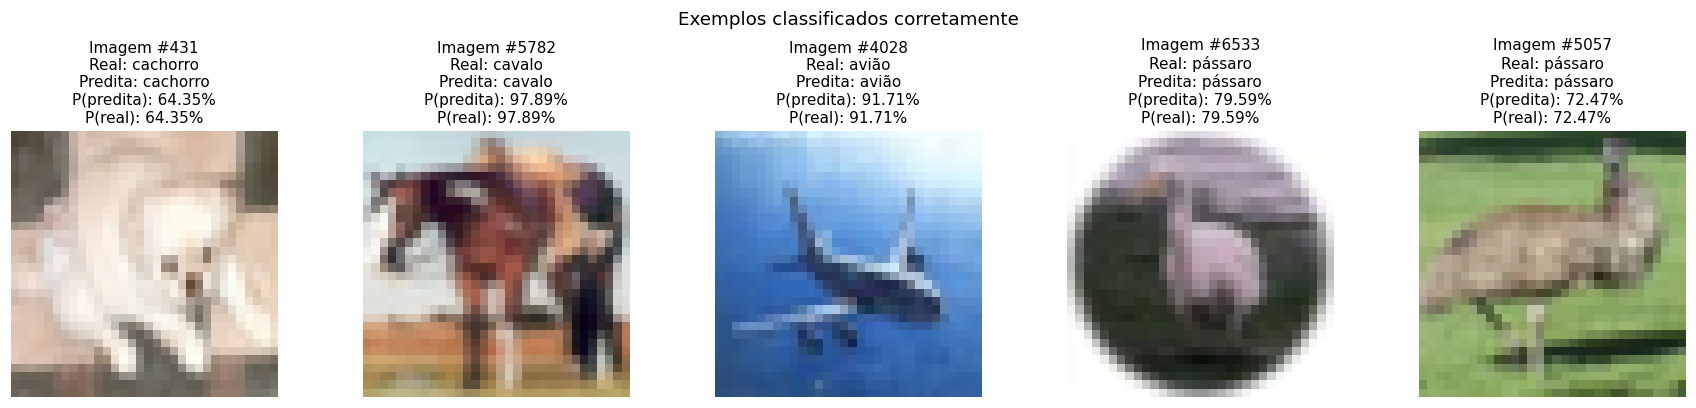

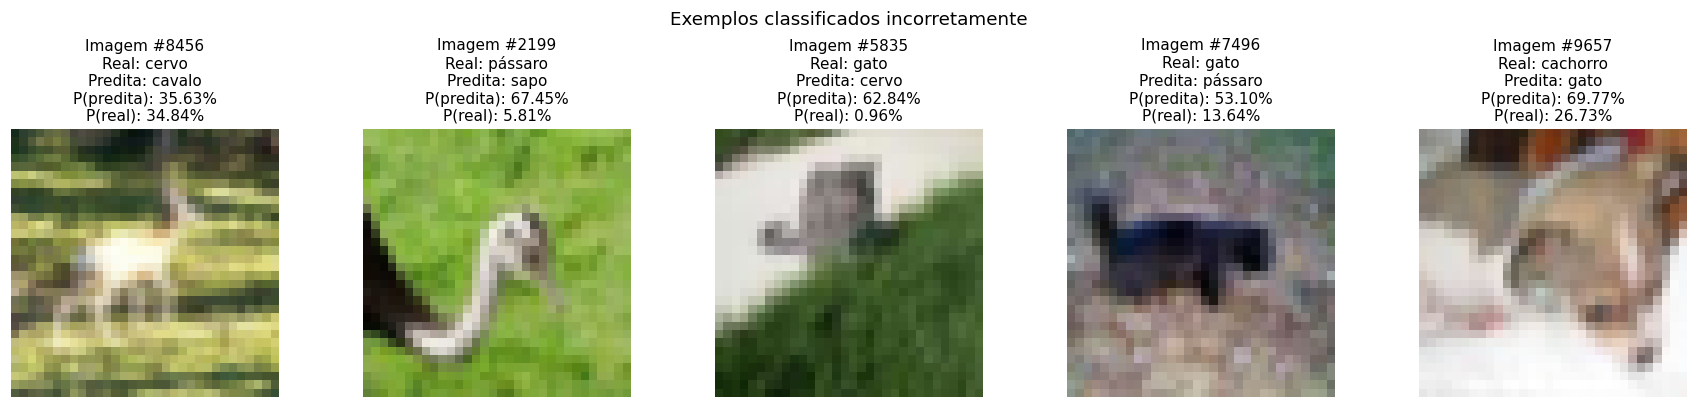

As probabilidades exibidas são os valores de softmax do modelo selecionado pela validação.


In [20]:
# (c) Exemplos corretamente e incorretamente classificados.
# Amostragem aleatória reprodutível; não escolhe apenas casos de alta confiança.
corretos = np.flatnonzero(predicoes == y_teste)
incorretos = np.flatnonzero(predicoes != y_teste)
rng_exemplos = np.random.default_rng(SEMENTE + 1)

def mostrar_exemplos(indices, titulo):
    if len(indices) == 0:
        print(titulo + ': nenhum exemplo disponível.')
        return np.array([], dtype=int)
    escolhidos = rng_exemplos.choice(indices, size=min(5, len(indices)), replace=False)
    fig, eixos = plt.subplots(1, len(escolhidos), figsize=(3.2 * len(escolhidos), 3.6),
                             squeeze=False, constrained_layout=True)
    for ax, indice in zip(eixos.ravel(), escolhidos):
        verdadeira = int(y_teste[indice])
        predita = int(predicoes[indice])
        ax.imshow(X_teste[indice].transpose(1, 2, 0))
        ax.set_title(f'Imagem #{indice}\nReal: {CLASSES[verdadeira]}\n'
                     f'Predita: {CLASSES[predita]}\nP(predita): {probabilidades[indice, predita]:.2%}\n'
                     f'P(real): {probabilidades[indice, verdadeira]:.2%}', fontsize=10)
        ax.axis('off')
    fig.suptitle(titulo)
    fig.savefig(SAIDA / ('q4_exemplos_incorretos.png' if 'incorretamente' in titulo else 'q4_exemplos_corretos.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return escolhidos

exemplos_corretos = mostrar_exemplos(corretos, 'Exemplos classificados corretamente')
exemplos_incorretos = mostrar_exemplos(incorretos, 'Exemplos classificados incorretamente')
assert np.all(predicoes[exemplos_corretos] == y_teste[exemplos_corretos])
assert np.all(predicoes[exemplos_incorretos] != y_teste[exemplos_incorretos])
print('As probabilidades exibidas são os valores de softmax do modelo selecionado pela validação.')

## FIM DA QUESTÃO 4 — Conferência dos resultados

**Questão 4(a):** verificar a exibição dos **16 filtros RGB** da primeira camada, a evolução dos filtros e o comentário qualitativo sobre padrões locais.

**Questão 4(b):** verificar os mapas de ativação de **cinco imagens distintas** do conjunto de teste, as respectivas imagens originais, as sobreposições e as observações qualitativas das regiões ativadas.

**Questão 4(c):** verificar os exemplos de classificações **corretas e incorretas**, cada um com imagem original, classe verdadeira, classe predita e probabilidade estimada.

**Vínculo com a Questão 3:** a mensagem **“Verificado: CNN da Questão 4 = CNN selecionada e avaliada na Questão 3”** confirma por comparação de todos os parâmetros que o modelo utilizado nas duas questões é o mesmo.

**Limitações científicas:** mapas de ativação não são explicações causais. Uma única divisão e uma única semente não medem a variabilidade do desempenho. Os resultados numéricos são gerados ao executar as células com o CIFAR-10 oficial.

---

### Entrega do notebook completo

Após executar tudo, confira que **as duas partes** possuem todas as saídas visíveis, salve o notebook no Colab e exporte como **`.ipynb`**, preservando os gráficos e resultados das Questões 3 e 4.